# Experiment Results Analysis

## What we collect

| Detail | Info |
| --- | --- |
| Sample | **179 GBIF Datasets: `ID`, `Nr Data Files`, `PDF Bytes`, `PDF Nr Pages`, `DDir`** |
| Independent Variable | **Metadata Schema: `DwC-T`, `EML`** |
| Treatment | **_massi_: w/ `Data File Provider`, w/ `Data Paper Provider`** |
| Dependent Variables | **`Nr Parseable`, `COR`, `SIMstr`, `SIMsemT`, `SIMsemA`** |
| Supporting Insights | **`success`, `size`, `size+a`, `depth`, `out`, `JIPn`, `JIPp`, `APTEDsim`, `APTEDbr`** |

## What we report

We report the following metrics: 

1. Task Accomplishment
    1. Syntactical correspondence.
    2. Structural tree similarity.
    3. Semantic value similarity.
2. Work Distribution
    1. Architect involvement balance.

## Notebook structure

This notebook performs all involved analyses above.


## Utilities

Before we start, we set up local dependencies.

In [1]:
!cd ../ && pip install -v . --group=dev --group=observability --group=analysis

Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
Processing ./.
  Running command installing build dependencies
  Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/95/9c/c510029fc6ef33a6275cd2c5d3cecd6613dfd6aa401d57c54f1c18852ccf/setuptools-84.0.0-py3-none-any.whl.metadata
    Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl (818 kB)
  ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
  torch 2.12.0 requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  e

In [2]:
import warnings
from lxml import etree
import apted
import massi.agents.tools as matls
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import tol_colors as tcls
import itertools as itlx
import json
from pathlib import Path
import re 
from typing import TypedDict, Any
from IPython.display import display, display_markdown
from pprint import pprint

In [3]:
from sklearn.metrics.pairwise import cosine_similarity
COS_SIMILARITY_READY = False
try:
    # NOTE: this can not run natively on Intel mac anymore
    from sentence_transformers import SentenceTransformer
    COS_SIMILARITY_READY = True
except ImportError as e:
    COS_SIMILARITY_READY = False
    warnings.warn("FAILED TO IMPORT `sentence_transformers`")
    warnings.warn(str(e))
finally:
    print(f"{COS_SIMILARITY_READY=}")

COS_SIMILARITY_READY=True


In [114]:
from scipy.stats import mannwhitneyu, ttest_ind, normaltest, pearsonr

In [5]:
def cohen_d(s1, s2):
    """
    Computes Cohen's d for two pandas Series / numpy arrays.
    """
    n1, n2 = len(s1), len(s2)
    m1, m2 = np.mean(s1), np.mean(s2)
    v1, v2 = np.var(s1, ddof=1), np.var(s2, ddof=1)
    
    # Pooled standard deviation
    s_pooled = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
    
    if s_pooled == 0:
        return np.nan
        
    return (m1 - m2) / s_pooled

In [6]:
tcls.set_default_colors()
plt.set_cmap(mpl.cm.tab20)

New config line: axes.prop_cycle : cycler('color', ['4477AA', 'EE6677', '228833', 'CCBB44', '66CCEE', 'AA3377', 'BBBBBB'])
Injecting line in file '/Users/mitjaorlov/.matplotlib/matplotlibrc'


<Figure size 640x480 with 0 Axes>

## Data Access

Reusable for prefixing data access.

In [7]:
EXPERIMENT_BASE_DIR = "../_data/gbif_data_archive/"

def grounded_path(suffix: str | Path) -> Path:
    return Path(EXPERIMENT_BASE_DIR) / suffix

### Data Analyses: DuckDB

Setting up DuckDB for use in the notebook.

In [8]:
from duckdb.sqltypes import VARCHAR
import duckdb as ddb

In [9]:
%config SqlMagic.autopandas = True
%load_ext sql
conn = ddb.connect()
%sql conn --alias duckdb

The 'toml' package isn't installed. To load settings from pyproject.toml or ~/.jupysql/config, install with: pip install toml

## Step 0: Prepare Local Table

In [10]:
%%sql
CREATE OR REPLACE TABLE experiment_log AS 
    FROM "./experiment_cross_scenarios_cases.log.csv";

Running query in 'duckdb'

,Count
0,716


## Step 1: Sample, IV, Treatment Data Info

### Computing

In [11]:
%%sql experiment_cases <<
WITH prep_gbif_cases AS (
    SELECT 
        case_id,
        "schema" as mschema,
        "strategy" as treatment,
        replace(
            replace(treatment, 'data-focus', 'data-file-provider'),
            'author-focus', 'data-paper-provider'
        ) as treatment_repl,
        replace(
            replace(
                replace(
                    dwca_zip_info, '''', '"'
                ), 'False', 'false'
            ), 'True', 'true'
        ) AS j_dwca_info,
        replace(
            replace(
                replace(
                    paper_download_info, '''', '"'
                ), 'False', 'false'
            ), 'True', 'true'
        ) AS j_paper_info,
        json_extract(
            j_dwca_info, 
            '$.nr_xml_files'
        ) AS nr_xml_files,
        json_extract(
            j_dwca_info, 
            '$.total_file_count'
        ) AS nr_all_files,
        (nr_all_files::INT - nr_xml_files::INT) AS nr_data_files, 
        json_extract(
            j_paper_info, 
            '$.file_size_bytes'
        ) AS pdf_bytes, 
        json_extract(
            j_paper_info, 
            '$.nr_pages'
        ) AS pdf_nr_pages,
        ground_truth_metadata_dwc,
        ground_truth_metadata_eml,
        working_copy_data_dir as ddir,
    -- FROM "../../runtime/gbif_cases.csv"
    FROM experiment_log
)
SELECT 
    case_id, 
    mschema, 
    treatment,
    treatment_repl,
    nr_data_files::INT as nr_data_files, 
    pdf_bytes::INT as pdf_bytes, 
    pdf_nr_pages::INT as pdf_nr_pages, 
    ground_truth_metadata_dwc,
    ground_truth_metadata_eml,
    ddir
FROM prep_gbif_cases;

Running query in 'duckdb'

### Reporting

In [12]:
experiment_cases.columns

Index(['case_id', 'mschema', 'treatment', 'treatment_repl', 'nr_data_files',
       'pdf_bytes', 'pdf_nr_pages', 'ground_truth_metadata_dwc',
       'ground_truth_metadata_eml', 'ddir'],
      dtype='str')

In [13]:
experiment_cases.head()

,case_id,mschema,treatment,treatment_repl,nr_data_files,pdf_bytes,pdf_nr_pages,ground_truth_metadata_dwc,ground_truth_metadata_eml,ddir
0,0,dwc,data-focus,data-file-provider,2,486786,14,ground_truth/data/000-6f97bcef-7324-3425-bb72-...,ground_truth/data/000-6f97bcef-7324-3425-bb72-...,working_copy/data/000-6f97bcef-7324-3425-bb72-...
1,1,dwc,data-focus,data-file-provider,1,700648,20,ground_truth/data/001-2fee34a0-a302-3c12-8916-...,ground_truth/data/001-2fee34a0-a302-3c12-8916-...,working_copy/data/001-2fee34a0-a302-3c12-8916-...
2,2,dwc,data-focus,data-file-provider,2,408932,18,ground_truth/data/002-325b19cf-6c16-3147-b8db-...,ground_truth/data/002-325b19cf-6c16-3147-b8db-...,working_copy/data/002-325b19cf-6c16-3147-b8db-...
3,3,dwc,data-focus,data-file-provider,2,918075,20,ground_truth/data/003-d72b6b4f-0fb1-301e-81d0-...,ground_truth/data/003-d72b6b4f-0fb1-301e-81d0-...,working_copy/data/003-d72b6b4f-0fb1-301e-81d0-...
4,4,dwc,data-focus,data-file-provider,3,516962,19,ground_truth/data/004-93ed8a30-2f05-37c7-a371-...,ground_truth/data/004-93ed8a30-2f05-37c7-a371-...,working_copy/data/004-93ed8a30-2f05-37c7-a371-...


In [14]:
experiment_cases.describe(include="all")

,case_id,mschema,treatment,treatment_repl,nr_data_files,pdf_bytes,pdf_nr_pages,ground_truth_metadata_dwc,ground_truth_metadata_eml,ddir
count,716.000000,716,716,716,716.000000,7.160000e+02,716.000000,716,716,716
unique,NaN,2,2,2,NaN,NaN,NaN,179,179,179
top,NaN,dwc,data-focus,data-file-provider,NaN,NaN,NaN,ground_truth/data/000-6f97bcef-7324-3425-bb72-...,ground_truth/data/000-6f97bcef-7324-3425-bb72-...,working_copy/data/000-6f97bcef-7324-3425-bb72-...
freq,NaN,358,358,358,NaN,NaN,NaN,4,4,4
mean,89.000000,NaN,NaN,NaN,1.569832,1.097365e+06,14.134078,NaN,NaN,NaN
std,51.708164,NaN,NaN,NaN,0.701156,1.216402e+06,8.795034,NaN,NaN,NaN
min,0.000000,NaN,NaN,NaN,1.000000,4.090000e+02,1.000000,NaN,NaN,NaN
25%,44.000000,NaN,NaN,NaN,1.000000,3.777540e+05,9.000000,NaN,NaN,NaN
50%,89.000000,NaN,NaN,NaN,1.000000,6.099190e+05,13.000000,NaN,NaN,NaN
75%,134.000000,NaN,NaN,NaN,2.000000,1.495143e+06,18.000000,NaN,NaN,NaN


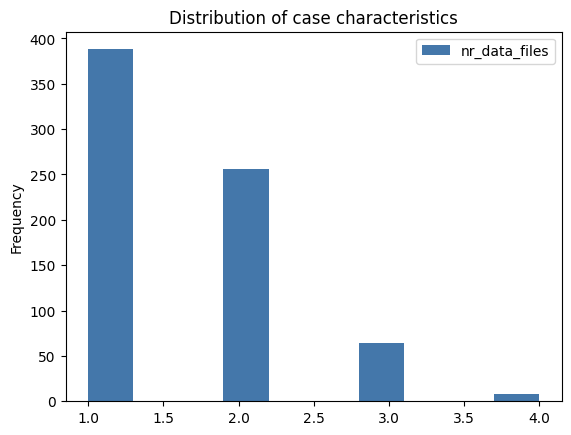

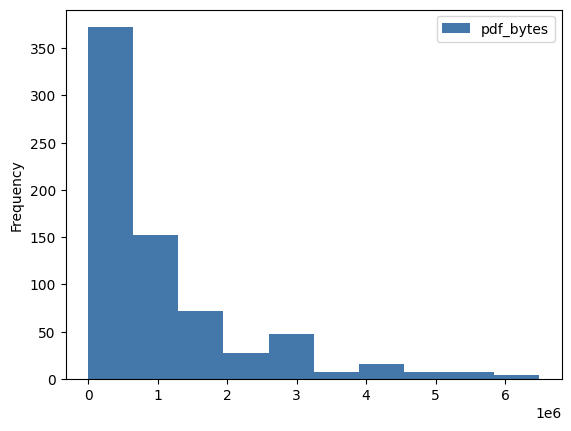

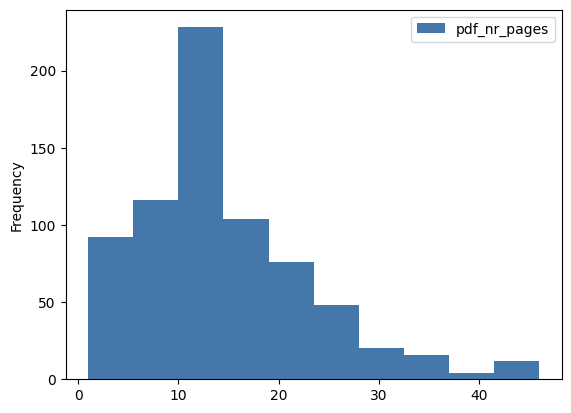

In [15]:
ax = experiment_cases.plot.hist(y="nr_data_files")
ax.set_title("Distribution of case characteristics")
experiment_cases.plot.hist(y="pdf_bytes")
experiment_cases.plot.hist(y="pdf_nr_pages")
plt.show()

In [16]:
experiment_cases[[
    "nr_data_files",
    "pdf_bytes",
    "pdf_nr_pages",
]].corr("pearson")

,nr_data_files,pdf_bytes,pdf_nr_pages
nr_data_files,1.000000,0.164903,0.100086
pdf_bytes,0.164903,1.000000,0.077866
pdf_nr_pages,0.100086,0.077866,1.000000


In [17]:
experiment_cases.describe()

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages
count,716.000000,716.000000,7.160000e+02,716.000000
mean,89.000000,1.569832,1.097365e+06,14.134078
std,51.708164,0.701156,1.216402e+06,8.795034
min,0.000000,1.000000,4.090000e+02,1.000000
25%,44.000000,1.000000,3.777540e+05,9.000000
50%,89.000000,1.000000,6.099190e+05,13.000000
75%,134.000000,2.000000,1.495143e+06,18.000000
max,178.000000,4.000000,6.490174e+06,46.000000


In [18]:
# One sample for all four configurations:
for name, group in experiment_cases.groupby(["mschema","treatment_repl"]):
    display(name)
    display(group.describe())

('dwc', 'data-file-provider')

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages
count,179.000000,179.000000,1.790000e+02,179.000000
mean,89.000000,1.569832,1.097365e+06,14.134078
std,51.816986,0.702632,1.218962e+06,8.813544
min,0.000000,1.000000,4.090000e+02,1.000000
25%,44.500000,1.000000,3.787995e+05,9.000000
50%,89.000000,1.000000,6.099190e+05,13.000000
75%,133.500000,2.000000,1.490002e+06,18.000000
max,178.000000,4.000000,6.490174e+06,46.000000


('dwc', 'data-paper-provider')

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages
count,179.000000,179.000000,1.790000e+02,179.000000
mean,89.000000,1.569832,1.097365e+06,14.134078
std,51.816986,0.702632,1.218962e+06,8.813544
min,0.000000,1.000000,4.090000e+02,1.000000
25%,44.500000,1.000000,3.787995e+05,9.000000
50%,89.000000,1.000000,6.099190e+05,13.000000
75%,133.500000,2.000000,1.490002e+06,18.000000
max,178.000000,4.000000,6.490174e+06,46.000000


('eml', 'data-file-provider')

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages
count,179.000000,179.000000,1.790000e+02,179.000000
mean,89.000000,1.569832,1.097365e+06,14.134078
std,51.816986,0.702632,1.218962e+06,8.813544
min,0.000000,1.000000,4.090000e+02,1.000000
25%,44.500000,1.000000,3.787995e+05,9.000000
50%,89.000000,1.000000,6.099190e+05,13.000000
75%,133.500000,2.000000,1.490002e+06,18.000000
max,178.000000,4.000000,6.490174e+06,46.000000


('eml', 'data-paper-provider')

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages
count,179.000000,179.000000,1.790000e+02,179.000000
mean,89.000000,1.569832,1.097365e+06,14.134078
std,51.816986,0.702632,1.218962e+06,8.813544
min,0.000000,1.000000,4.090000e+02,1.000000
25%,44.500000,1.000000,3.787995e+05,9.000000
50%,89.000000,1.000000,6.099190e+05,13.000000
75%,133.500000,2.000000,1.490002e+06,18.000000
max,178.000000,4.000000,6.490174e+06,46.000000


### Cleanup

In [19]:
try:
    del experiment_cases
except Exception as e:
    print(e)

## Step 2: `+` Supporting Insights

### Tree Operations

In [20]:
def parse_xml_file(path: str | Path):
    return etree.parse(path)

def parse_xml_string(data: str):
    return etree.fromstring(data.encode())

def parse_xml_content(xml_content: Any):
    return parse_xml_string(str(xml_content))

def resolve_xml_content(r: dict) -> str:
    return r['resolutions'][0]['working_copy_xml_blueprint']["content"]    

def cleanup_gap_failures(xml_data:str):
    return re.sub(r"\{\{GAP_([0-9]+)[^\}]*\}+", r"not-derived-\1", xml_data)

def cleanup_special_characters(xml_data:str):
    return re.sub("&", "&amp;", xml_data)

In [245]:
class NodeInfo(TypedDict):
    tag: str
    degree: int
    depth: int
    is_leaf: bool # <=> (degree == 0) 
    attributes: str # <-- json.dumps(attributes)
    attributes_count: int # <-- |attributes.keys()|
    text: str
    path: str | None

class TreeInfo(TypedDict):
    size: int # <-- |_nodes|
    size_with_attributes: int # <-- SUM(n.attributes_count for n in _nodes)
    _nodes: list[NodeInfo]

def project_public(d: dict):
    public_data = {k:v for k,v in d.items() if not str(k).startswith("_")}
    return public_data

In [244]:
def get_root(tree):
    """Retrieves a root of the provided tree"""
    if hasattr(tree, "getroot"):
        return tree.getroot()
    return tree

def get_tree_info(tree) -> TreeInfo:
    return _get_tree_info(tree)

def _get_tree_info(tree) -> TreeInfo:
    root = etree.ElementTree(get_root(tree))
    
    def _get_node_info(node) -> NodeInfo:
        return {
            "tag": "comment" if isinstance(node, etree._Comment) else node.tag,
            "depth": len(list(node.iterancestors())),
            "degree": len(node),
            "is_leaf": len(node) == 0,
            "attributes": dict(node.attrib.items()),
            "attributes_count": len(node.attrib.keys()),
            "has_attributes": bool(node.attrib),
            "text": node.text,
            "has_text": bool(node.text.strip()) if node.text else False,
            "path": None if isinstance(node, etree._Comment) else root.getelementpath(node)
        }
    
    nodes_info = list(map(_get_node_info, root.iter()))
    return {
        "size": len(nodes_info), 
        "size_with_attributes": len(nodes_info) + sum(n["attributes_count"] for n in nodes_info),
        "_nodes": nodes_info
    }

### Computing

In [246]:
def outcome_json_to_tree_info_json(outcome_json: str) -> str:
    outcome_dict = json.loads(outcome_json)
    if ('resolutions' not in outcome_dict):
        return json.dumps({'parsed': False, 'tree_info': None, 'error': "'resolutions' key is not found"})
    try:
        wc_metadata_xml = resolve_xml_content(outcome_dict)
        wc_metadata_xml_clean = cleanup_special_characters(cleanup_gap_failures(wc_metadata_xml))
        wc_metadata_tree = parse_xml_content(wc_metadata_xml_clean)
        wc_metadata_tree_info = get_tree_info(wc_metadata_tree)
        return json.dumps({'parsed': True, 'tree_info': wc_metadata_tree_info, 'error': None})
    except Exception as e:
        return json.dumps({'parsed': False, 'tree_info': None, 'error': str(e)})

In [247]:
def ground_truth_path_to_tree_info_json(ground_truth_path: str) -> str:
    try:
        wc_metadata_tree = parse_xml_file(grounded_path(ground_truth_path))
        wc_metadata_tree_info = get_tree_info(wc_metadata_tree)
        return json.dumps({'parsed': True, 'tree_info': wc_metadata_tree_info, 'error': None})
    except Exception as e:
        return json.dumps({'parsed': False, 'tree_info': None, 'error': str(e)})

In [248]:
for f in [
    outcome_json_to_tree_info_json, ground_truth_path_to_tree_info_json
]:
    try:
        conn.remove_function(f.__name__)
    except Exception as e:
        print(f"Function not found: {e}")
    conn.create_function(f.__name__, f)

In [249]:
%%sql
CREATE OR REPLACE TABLE prep_gbif_cases AS (
-- WITH prep_gbif_cases AS (
    SELECT 
    -- experiment run details
        case_id,
        "schema" as mschema,
        "strategy" as treatment,
        replace(
            replace(treatment, 'data-focus', 'data-file-provider'),
            'author-focus', 'data-paper-provider'
        ) as treatment_repl,
        replace(
            replace(
                replace(
                    dwca_zip_info, '''', '"'
                ), 'False', 'false'
            ), 'True', 'true'
        ) AS j_dwca_info,
        replace(
            replace(
                replace(
                    paper_download_info, '''', '"'
                ), 'False', 'false'
            ), 'True', 'true'
        ) AS j_paper_info,
        json_extract(
            j_dwca_info, 
            '$.nr_xml_files'
        ) AS nr_xml_files,
        json_extract(
            j_dwca_info, 
            '$.total_file_count'
        ) AS nr_all_files,
        (nr_all_files::INT - nr_xml_files::INT) AS nr_data_files, 
        json_extract(
            j_paper_info, 
            '$.file_size_bytes'
        ) AS pdf_bytes, 
        json_extract(
            j_paper_info, 
            '$.nr_pages'
        ) AS pdf_nr_pages,
        ground_truth_metadata_dwc,
        ground_truth_metadata_eml,
        working_copy_data_dir as ddir,
    
    -- supporting details: constructed
        success,
        outcome_json,
        outcome_json_to_tree_info_json(outcome_json) as tree_info_json,
        json_extract(tree_info_json, '$.parsed')::BOOLEAN as parsed,
        json_extract(tree_info_json, '$.tree_info.size')::INT as tree_size,
        json_extract(tree_info_json, '$.tree_info.size_with_attributes')::INT as tree_size_with_attrs,
        json_extract(tree_info_json, '$.tree_info._nodes') as tree_nodes,

    -- supporting details: ground truth
        IF(mschema = 'dwc', ground_truth_metadata_dwc, ground_truth_metadata_eml) as ground_truth_metadata_path,
        ground_truth_path_to_tree_info_json(ground_truth_metadata_path) as gt_tree_info_json,
        json_extract(gt_tree_info_json, '$.parsed')::BOOLEAN as gt_parsed,
        json_extract(gt_tree_info_json, '$.tree_info.size')::INT as gt_tree_size,
        json_extract(gt_tree_info_json, '$.tree_info.size_with_attributes')::INT as gt_tree_size_with_attrs,
        json_extract(gt_tree_info_json, '$.tree_info._nodes') as gt_tree_nodes
    FROM experiment_log
);
CREATE OR REPLACE TABLE experiment_constructed_tree_info_grand AS 
    SELECT 
        case_id, 
        mschema, 
        treatment,
        treatment_repl,
        nr_data_files::INT as nr_data_files, 
        pdf_bytes::INT as pdf_bytes, 
        pdf_nr_pages::INT as pdf_nr_pages, 
        ground_truth_metadata_dwc,
        ground_truth_metadata_eml,
        ddir,
        success,
        outcome_json,
        tree_info_json,
        parsed,
        parsed::INT as parsed_int, 
        tree_size,
        tree_size_with_attrs,
        tree_nodes,
        gt_tree_info_json,
        gt_parsed,
        gt_parsed::INT as parsed_int, 
        gt_tree_size,
        gt_tree_size_with_attrs,
        gt_tree_nodes
    FROM prep_gbif_cases;
CREATE OR REPLACE TABLE experiment_constructed_tree_info_nodes AS 
    SELECT 
        case_id, 
        mschema, 
        treatment,
        treatment_repl,
        nr_data_files::INT as nr_data_files, 
        pdf_bytes::INT as pdf_bytes, 
        pdf_nr_pages::INT as pdf_nr_pages, 
        ground_truth_metadata_dwc,
        ground_truth_metadata_eml,
        ddir,
        success,
        outcome_json,
        tree_info_json,
        parsed,
        je.*,
        json_extract(je.value, '$.tag') as node_tag,
        json_extract(je.value, '$.path') as node_path,
        json_extract(je.value, '$.depth')::INT as node_depth,
        json_extract(je.value, '$.degree')::INT as node_degree,
        json_extract(je.value, '$.text') as node_text,
        json_extract(je.value, '$.has_text')::BOOLEAN as node_has_text,
        json_extract(je.value, '$.attributes') as node_attributes,
        json_extract(je.value, '$.has_attributes')::BOOLEAN as node_has_attributes,
    FROM prep_gbif_cases AS c,
        json_each(c.tree_nodes) AS je
    WHERE parsed = True;
CREATE OR REPLACE TABLE experiment_gt_tree_info_nodes AS 
    SELECT 
        case_id, 
        mschema, 
        treatment,
        treatment_repl,
        nr_data_files::INT as nr_data_files, 
        pdf_bytes::INT as pdf_bytes, 
        pdf_nr_pages::INT as pdf_nr_pages, 
        ground_truth_metadata_dwc,
        ground_truth_metadata_eml,
        ddir,
        success,
        outcome_json,
        tree_info_json,
        parsed,
        gt_tree_info_json,
        gt_parsed,
        je.*,
        json_extract(je.value, '$.tag') as gt_node_tag,
        json_extract(je.value, '$.path') as gt_node_path,
        json_extract(je.value, '$.depth')::INT as gt_node_depth,
        json_extract(je.value, '$.degree')::INT as gt_node_degree,
        json_extract(je.value, '$.text') as gt_node_text,
        json_extract(je.value, '$.has_text')::BOOLEAN as gt_node_has_text,
        json_extract(je.value, '$.attributes') as gt_node_attributes,
        json_extract(je.value, '$.has_attributes')::BOOLEAN as gt_node_has_attributes,
    FROM prep_gbif_cases AS c,
        json_each(c.gt_tree_nodes) AS je
    WHERE parsed = True;

Running query in 'duckdb'

,Count
0,102023


In [250]:
%%sql
SELECT mschema, treatment_repl, COUNT(DISTINCT case_id)
FROM experiment_constructed_tree_info_nodes
GROUP BY 1,2
ORDER BY 1,2

Running query in 'duckdb'

,mschema,treatment_repl,count(DISTINCT case_id)
0,dwc,data-file-provider,174
1,dwc,data-paper-provider,174
2,eml,data-file-provider,150
3,eml,data-paper-provider,148


In [251]:
%%sql
SELECT mschema, treatment_repl, COUNT(DISTINCT case_id)
FROM experiment_gt_tree_info_nodes
GROUP BY 1,2
ORDER BY 1,2

Running query in 'duckdb'

,mschema,treatment_repl,count(DISTINCT case_id)
0,dwc,data-file-provider,174
1,dwc,data-paper-provider,174
2,eml,data-file-provider,150
3,eml,data-paper-provider,148


### Reporting

> **Trees details**

In [27]:
%%sql experiment_tree_info_grand <<
SELECT * 
FROM experiment_constructed_tree_info_grand

Running query in 'duckdb'

In [28]:
%%sql experiment_tree_info_grand_dwc <<
SELECT *, 
  -- supporting details
    ground_truth_path_to_tree_info_json(ground_truth_metadata_dwc) as gt_tree_info_json,
    json_extract(gt_tree_info_json, '$.parsed')::BOOLEAN as gt_parsed,
    json_extract(gt_tree_info_json, '$.tree_info.size')::INT as gt_tree_size,
    json_extract(gt_tree_info_json, '$.tree_info.size_with_attributes')::INT as gt_tree_size_with_attrs,
    json_extract(gt_tree_info_json, '$.tree_info._nodes') as gt_tree_nodes
FROM experiment_constructed_tree_info_grand
WHERE mschema = 'dwc'

Running query in 'duckdb'

In [29]:
%%sql experiment_tree_info_node_dwc <<
WITH grand_source AS (
    SELECT *, 
      -- supporting details
        ground_truth_path_to_tree_info_json(ground_truth_metadata_dwc) as gt_tree_info_json
    FROM experiment_constructed_tree_info_grand
    WHERE mschema = 'dwc'
)
SELECT *,
    je.*,
    json_extract(je.value, '$.tag') as node_tag,
    json_extract(je.value, '$.depth')::INT as node_depth,
    json_extract(je.value, '$.degree')::INT as node_degree,
FROM grand_source AS c,
    json_each(c.tree_nodes) AS je
WHERE mschema = 'dwc'

Running query in 'duckdb'

In [30]:
experiment_tree_info_grand_dwc.describe()

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages,parsed_int,tree_size,tree_size_with_attrs,parsed_int_1,gt_tree_size,gt_tree_size_with_attrs,gt_tree_size_1,gt_tree_size_with_attrs_1
count,358.000000,358.000000,3.580000e+02,358.000000,358.000000,348.0,348.0,358.000000,348.0,348.0,356.0,356.0
mean,89.000000,1.569832,1.097365e+06,14.134078,0.972067,49.178161,142.818966,0.972067,49.178161,142.818966,49.089888,145.02809
std,51.744362,0.701647,1.217253e+06,8.801191,0.165011,22.724826,67.524349,0.165011,22.724826,67.524349,23.020207,68.771713
min,0.000000,1.000000,4.090000e+02,1.000000,0.000000,12.0,33.0,0.000000,12.0,33.0,12.0,34.0
25%,44.250000,1.000000,3.782768e+05,9.000000,1.000000,33.75,98.5,1.000000,33.75,98.5,33.0,97.0
50%,89.000000,1.000000,6.099190e+05,13.000000,1.000000,45.0,132.0,1.000000,45.0,132.0,45.0,133.5
75%,133.750000,2.000000,1.492572e+06,18.000000,1.000000,61.0,176.0,1.000000,61.0,176.0,61.0,180.0
max,178.000000,4.000000,6.490174e+06,46.000000,1.000000,190.0,565.0,1.000000,190.0,565.0,202.0,603.0


In [31]:
experiment_tree_info_node_dwc.describe()

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages,parsed_int,tree_size,tree_size_with_attrs,parsed_int_1,gt_tree_size,gt_tree_size_with_attrs,id,parent,id_1,parent_1,node_depth,node_degree
count,17114.000000,17114.000000,1.711400e+04,17114.000000,17114.0,17114.000000,17114.00000,17114.0,17114.000000,17114.00000,17114.000000,0.0,17114.000000,0.0,17114.000000,17114.000000
mean,89.126212,1.713918,1.208576e+06,14.389038,1.0,59.648942,173.91393,1.0,59.648942,173.91393,616.813895,<NA>,616.813895,<NA>,1.959332,0.979666
std,51.100051,0.759957,1.298036e+06,8.684366,0.0,31.232997,93.40314,0.0,31.232997,93.40314,523.570210,<NA>,523.570210,<NA>,0.377421,6.194254
min,0.000000,1.000000,4.090000e+02,1.000000,1.0,12.000000,33.00000,1.0,12.000000,33.00000,1.000000,<NA>,1.000000,<NA>,0.000000,0.000000
25%,45.000000,1.000000,3.973820e+05,9.000000,1.0,41.000000,120.00000,1.0,41.000000,120.00000,253.000000,<NA>,253.000000,<NA>,2.000000,0.000000
50%,91.000000,2.000000,6.711300e+05,13.000000,1.0,52.000000,153.00000,1.0,52.000000,153.00000,505.000000,<NA>,505.000000,<NA>,2.000000,0.000000
75%,134.000000,2.000000,1.633516e+06,19.000000,1.0,67.000000,196.00000,1.0,67.000000,196.00000,841.000000,<NA>,841.000000,<NA>,2.000000,0.000000
max,178.000000,4.000000,6.490174e+06,46.000000,1.0,190.000000,565.00000,1.0,190.000000,565.00000,3970.000000,<NA>,3970.000000,<NA>,3.000000,183.000000


In [32]:
%%sql experiment_tree_info_grand_eml <<
SELECT *,
  -- supporting details
    ground_truth_path_to_tree_info_json(ground_truth_metadata_eml) as gt_tree_info_json,
    json_extract(gt_tree_info_json, '$.parsed')::BOOLEAN as gt_parsed,
    json_extract(gt_tree_info_json, '$.tree_info.size')::INT as gt_tree_size,
    json_extract(gt_tree_info_json, '$.tree_info.size_with_attributes')::INT as gt_tree_size_with_attrs,
    json_extract(gt_tree_info_json, '$.tree_info._nodes') as gt_tree_nodes
FROM experiment_constructed_tree_info_grand
WHERE mschema = 'eml'

Running query in 'duckdb'

In [33]:
%%sql experiment_tree_info_node_eml <<
WITH grand_source AS (
    SELECT *, 
      -- supporting details
        ground_truth_path_to_tree_info_json(ground_truth_metadata_eml) as gt_tree_info_json
    FROM experiment_constructed_tree_info_grand
    WHERE mschema = 'eml'
)
SELECT *,
    je.*,
    json_extract(je.value, '$.tag') as node_tag,
    json_extract(je.value, '$.depth')::INT as node_depth,
    json_extract(je.value, '$.degree')::INT as node_degree,
FROM grand_source AS c,
    json_each(c.tree_nodes) AS je
WHERE mschema = 'eml'

Running query in 'duckdb'

In [34]:
experiment_tree_info_grand_eml.describe()

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages,parsed_int,tree_size,tree_size_with_attrs,parsed_int_1,gt_tree_size,gt_tree_size_with_attrs,gt_tree_size_1,gt_tree_size_with_attrs_1
count,358.000000,358.000000,3.580000e+02,358.000000,358.000000,298.0,298.0,358.000000,298.0,298.0,356.0,356.0
mean,89.000000,1.569832,1.097365e+06,14.134078,0.832402,41.285235,48.996644,0.832402,41.285235,48.996644,300.702247,318.988764
std,51.744362,0.701647,1.217253e+06,8.801191,0.374031,8.9696,10.214698,0.374031,8.9696,10.214698,495.152998,498.488905
min,0.000000,1.000000,4.090000e+02,1.000000,0.000000,32.0,37.0,0.000000,32.0,37.0,31.0,36.0
25%,44.250000,1.000000,3.782768e+05,9.000000,1.000000,34.0,41.0,1.000000,34.0,41.0,142.0,154.0
50%,89.000000,1.000000,6.099190e+05,13.000000,1.000000,40.0,48.0,1.000000,40.0,48.0,209.0,224.0
75%,133.750000,2.000000,1.492572e+06,18.000000,1.000000,47.0,55.0,1.000000,47.0,55.0,336.0,358.0
max,178.000000,4.000000,6.490174e+06,46.000000,1.000000,76.0,86.0,1.000000,76.0,86.0,6326.0,6347.0


In [35]:
experiment_tree_info_node_eml.describe()

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages,parsed_int,tree_size,tree_size_with_attrs,parsed_int_1,gt_tree_size,gt_tree_size_with_attrs,id,parent,id_1,parent_1,node_depth,node_degree
count,12303.000000,12303.000000,1.230300e+04,12303.000000,12303.0,12303.000000,12303.000000,12303.0,12303.000000,12303.000000,12303.000000,0.0,12303.000000,0.0,12303.000000,12303.000000
mean,89.858977,1.614078,1.117600e+06,14.189547,1.0,43.227424,51.180281,1.0,43.227424,51.180281,444.387954,<NA>,444.387954,<NA>,3.368203,0.975778
std,52.448902,0.706569,1.247027e+06,8.812300,0.0,9.597906,10.791435,0.0,9.597906,10.791435,286.673793,<NA>,286.673793,<NA>,1.225045,1.297321
min,0.000000,1.000000,4.090000e+02,1.000000,1.0,32.000000,37.000000,1.0,32.000000,37.000000,1.000000,<NA>,1.000000,<NA>,0.000000,0.000000
25%,45.000000,1.000000,3.777540e+05,8.000000,1.0,34.000000,42.000000,1.0,34.000000,42.000000,211.000000,<NA>,211.000000,<NA>,3.000000,0.000000
50%,90.000000,1.000000,5.826900e+05,13.000000,1.0,42.000000,51.000000,1.0,42.000000,51.000000,421.000000,<NA>,421.000000,<NA>,3.000000,1.000000
75%,136.000000,2.000000,1.495143e+06,18.000000,1.0,49.000000,58.000000,1.0,49.000000,58.000000,631.000000,<NA>,631.000000,<NA>,4.000000,2.000000
max,178.000000,4.000000,6.490174e+06,46.000000,1.0,76.000000,86.000000,1.0,76.000000,86.000000,1576.000000,<NA>,1576.000000,<NA>,7.000000,15.000000


In [36]:
experiment_tree_info_grand['log_pdf_bytes'] = np.log1p(experiment_tree_info_grand['pdf_bytes'])

In [37]:
experiment_groups_tree = experiment_tree_info_grand.groupby(["mschema", "treatment_repl"])

["('dwc', 'data-file-provider')" "('dwc', 'data-paper-provider')"
 "('eml', 'data-file-provider')" "('eml', 'data-paper-provider')"]
[179 179 179 179]


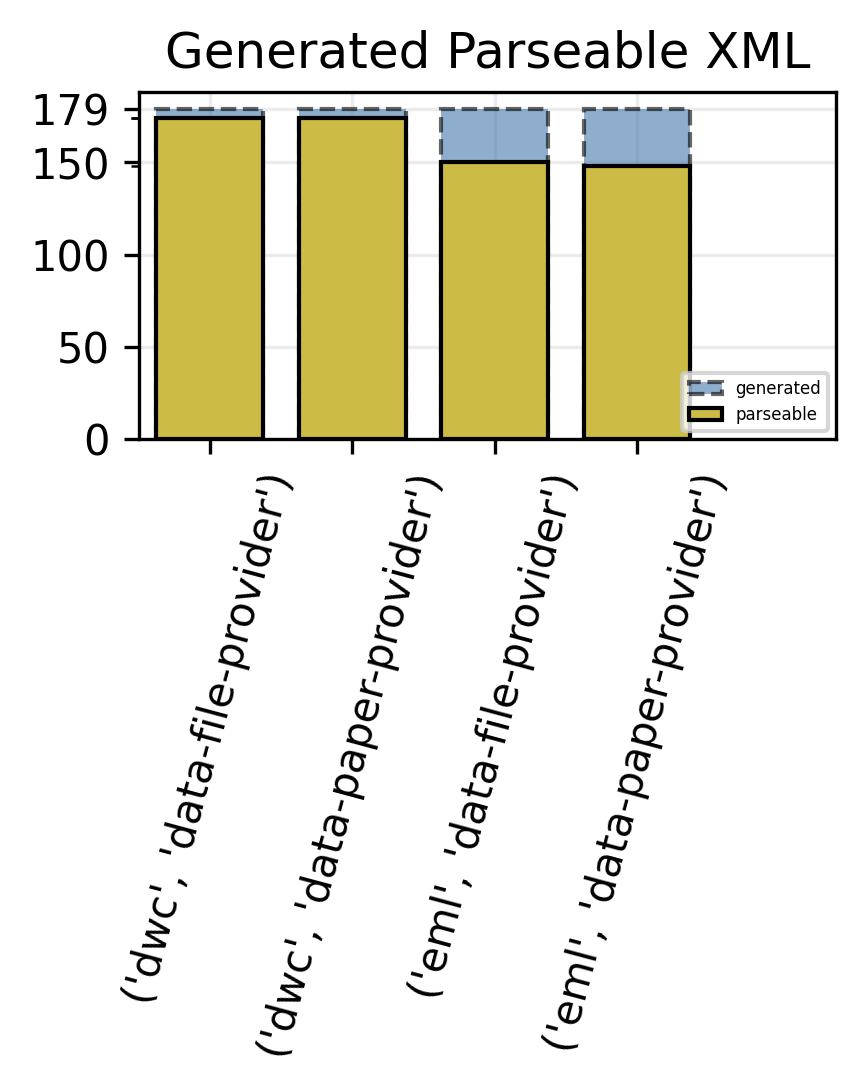

In [38]:
fig, ax = plt.subplots(1,1, dpi=300, figsize=(3, 1.5))

experiment_groups = np.array([str(g) for g, rs in experiment_groups_tree])
experiment_count = np.array([rs.shape[0] for g, rs in experiment_groups_tree])
ok_experiment_count = np.array([rs[rs["parsed"]].shape[0] for g, rs in experiment_groups_tree])

print(experiment_groups)
print(experiment_count)

ax.set_title("Generated Parseable XML")
ax.bar(experiment_groups, experiment_count, label="generated", color=tcls.bright[0], edgecolor="black", ls="--", alpha=0.6, width=0.75)
ax.bar(experiment_groups, ok_experiment_count, label="parseable", color=tcls.bright[3], edgecolor="black", width=0.75)
ax.set_yticks(ok_experiment_count, minor=True)
ax.set_xticks(experiment_groups, labels=experiment_groups, rotation=75)
ax.set_yticks([0, 50, 100, 150, 179])
ax.set_xlim(-0.5, 4.4)
ax.legend(fontsize=4, loc="lower right")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)

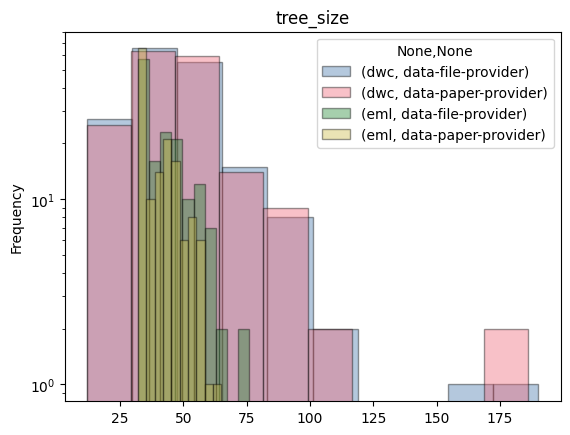

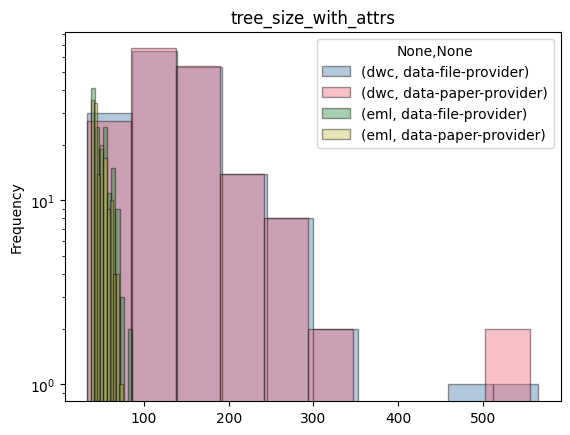

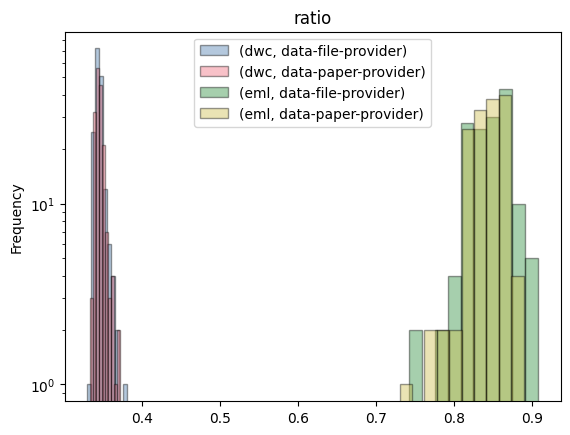

In [39]:
ax = None
for name,group in experiment_groups_tree:
    ax = group.plot.hist(y="tree_size", alpha=0.4, ax=ax, label=name, edgecolor="k", log=True)
    ax.set_title("tree_size")
plt.show()

ax = None
for name,group in experiment_groups_tree:
    ax = group.plot.hist(y="tree_size_with_attrs", alpha=0.4, ax=ax, label=name, edgecolor="k", log=True)
    ax.set_title("tree_size_with_attrs")
plt.show()

ax = None
for name,group in experiment_groups_tree:
    ax = (group["tree_size"] / group["tree_size_with_attrs"]).plot.hist(alpha=0.4, ax=ax, label=name, edgecolor="k", log=True)
    ax.legend()
    ax.set_title("ratio")

plt.show()

> **Correlation between parsing success and sample characterstics**

In [40]:
experiment_groups_tree[
    ["nr_data_files", "pdf_bytes", "log_pdf_bytes", "pdf_nr_pages", "parsed_int"]
].describe()

nr_data_files                                     \
                                    count      mean       std  min  25%  50%   
mschema treatment_repl                                                         
dwc     data-file-provider          179.0  1.569832  0.702632  1.0  1.0  1.0   
        data-paper-provider         179.0  1.569832  0.702632  1.0  1.0  1.0   
eml     data-file-provider          179.0  1.569832  0.702632  1.0  1.0  1.0   
        data-paper-provider         179.0  1.569832  0.702632  1.0  1.0  1.0   

                                      pdf_bytes                ...  \
                             75%  max     count          mean  ...   
mschema treatment_repl                                         ...   
dwc     data-file-provider   2.0  4.0     179.0  1.097365e+06  ...   
        data-paper-provider  2.0  4.0     179.0  1.097365e+06  ...   
eml     data-file-provider   2.0  4.0     179.0  1.097365e+06  ...   
        data-paper-provider  2.0  4.0     179.0  1.097365e+06  ...   

                            pdf_nr_pages       parsed_int                      \
                                     75%   max      count      mean       std   
mschema treatment_repl                                                          
dwc     data-file-provider          18.0  46.0      179.0  0.972067  0.165243   
        data-paper-provider         18.0  46.0      179.0  0.972067  0.165243   
eml     data-file-provider          18.0  46.0      179.0  0.837989  0.369495   
        data-paper-provider         18.0  46.0      179.0  0.826816  0.379468   

                                                      
                             min  25%  50%  75%  max  
mschema treatment_repl                                
dwc     data-file-provider   0.0  1.0  1.0  1.0  1.0  
        data-paper-provider  0.0  1.0  1.0  1.0  1.0  
eml     data-file-provider   0.0  1.0  1.0  1.0  1.0  
        data-paper-provider  0.0  1.0  1.0  1.0  1.0  

[4 rows x 40 columns]

In [41]:
experiment_groups_tree[
    ["nr_data_files", "pdf_bytes", "log_pdf_bytes", "pdf_nr_pages", "parsed_int"]
].corr("pearson")

nr_data_files  pdf_bytes  \
mschema treatment_repl                                                
dwc     data-file-provider  nr_data_files       1.000000   0.164903   
                            pdf_bytes           0.164903   1.000000   
                            log_pdf_bytes       0.181421   0.579863   
                            pdf_nr_pages        0.100086   0.077866   
                            parsed_int         -0.200847   0.009867   
        data-paper-provider nr_data_files       1.000000   0.164903   
                            pdf_bytes           0.164903   1.000000   
                            log_pdf_bytes       0.181421   0.579863   
                            pdf_nr_pages        0.100086   0.077866   
                            parsed_int         -0.007299  -0.069143   
eml     data-file-provider  nr_data_files       1.000000   0.164903   
                            pdf_bytes           0.164903   1.000000   
                            log_pdf_bytes       0.181421   0.579863   
                            pdf_nr_pages        0.100086   0.077866   
                            parsed_int          0.011364   0.035015   
        data-paper-provider nr_data_files       1.000000   0.164903   
                            pdf_bytes           0.164903   1.000000   
                            log_pdf_bytes       0.181421   0.579863   
                            pdf_nr_pages        0.100086   0.077866   
                            parsed_int          0.077220  -0.016647   

                                           log_pdf_bytes  pdf_nr_pages  \
mschema treatment_repl                                                   
dwc     data-file-provider  nr_data_files       0.181421      0.100086   
                            pdf_bytes           0.579863      0.077866   
                            log_pdf_bytes       1.000000      0.434693   
                            pdf_nr_pages        0.434693      1.000000   
                            parsed_int         -0.048940     -0.039847   
        data-paper-provider nr_data_files       0.181421      0.100086   
                            pdf_bytes           0.579863      0.077866   
                            log_pdf_bytes       1.000000      0.434693   
                            pdf_nr_pages        0.434693      1.000000   
                            parsed_int         -0.043839     -0.051419   
eml     data-file-provider  nr_data_files       0.181421      0.100086   
                            pdf_bytes           0.579863      0.077866   
                            log_pdf_bytes       1.000000      0.434693   
                            pdf_nr_pages        0.434693      1.000000   
                            parsed_int          0.067035      0.051561   
        data-paper-provider nr_data_files       0.181421      0.100086   
                            pdf_bytes           0.579863      0.077866   
                            log_pdf_bytes       1.000000      0.434693   
                            pdf_nr_pages        0.434693      1.000000   
                            parsed_int         -0.095348     -0.155957   

                                           parsed_int  
mschema treatment_repl                                 
dwc     data-file-provider  nr_data_files   -0.200847  
                            pdf_bytes        0.009867  
                            log_pdf_bytes   -0.048940  
                            pdf_nr_pages    -0.039847  
                            parsed_int       1.000000  
        data-paper-provider nr_data_files   -0.007299  
                            pdf_bytes       -0.069143  
                            log_pdf_bytes   -0.043839  
                            pdf_nr_pages    -0.051419  
                            parsed_int       1.000000  
eml     data-file-provider  nr_data_files    0.011364  
                            pdf_bytes        0.035015  
                            log_pdf_bytes    0.067035  
           

In [42]:
experiment_groups_tree[
    ["nr_data_files", "pdf_bytes", "log_pdf_bytes", "pdf_nr_pages", "parsed_int"]
].corr("spearman")

nr_data_files  pdf_bytes  \
mschema treatment_repl                                                
dwc     data-file-provider  nr_data_files       1.000000   0.093357   
                            pdf_bytes           0.093357   1.000000   
                            log_pdf_bytes       0.093357   1.000000   
                            pdf_nr_pages        0.148218   0.231727   
                            parsed_int         -0.204272  -0.031496   
        data-paper-provider nr_data_files       1.000000   0.093357   
                            pdf_bytes           0.093357   1.000000   
                            log_pdf_bytes       0.093357   1.000000   
                            pdf_nr_pages        0.148218   0.231727   
                            parsed_int          0.002944  -0.000656   
eml     data-file-provider  nr_data_files       1.000000   0.093357   
                            pdf_bytes           0.093357   1.000000   
                            log_pdf_bytes       0.093357   1.000000   
                            pdf_nr_pages        0.148218   0.231727   
                            parsed_int          0.020740   0.013645   
        data-paper-provider nr_data_files       1.000000   0.093357   
                            pdf_bytes           0.093357   1.000000   
                            log_pdf_bytes       0.093357   1.000000   
                            pdf_nr_pages        0.148218   0.231727   
                            parsed_int          0.085106  -0.090577   

                                           log_pdf_bytes  pdf_nr_pages  \
mschema treatment_repl                                                   
dwc     data-file-provider  nr_data_files       0.093357      0.148218   
                            pdf_bytes           1.000000      0.231727   
                            log_pdf_bytes       1.000000      0.231727   
                            pdf_nr_pages        0.231727      1.000000   
                            parsed_int         -0.031496     -0.042375   
        data-paper-provider nr_data_files       0.093357      0.148218   
                            pdf_bytes           1.000000      0.231727   
                            log_pdf_bytes       1.000000      0.231727   
                            pdf_nr_pages        0.231727      1.000000   
                            parsed_int         -0.000656     -0.091319   
eml     data-file-provider  nr_data_files       0.093357      0.148218   
                            pdf_bytes           1.000000      0.231727   
                            log_pdf_bytes       1.000000      0.231727   
                            pdf_nr_pages        0.231727      1.000000   
                            parsed_int          0.013645      0.058174   
        data-paper-provider nr_data_files       0.093357      0.148218   
                            pdf_bytes           1.000000      0.231727   
                            log_pdf_bytes       1.000000      0.231727   
                            pdf_nr_pages        0.231727      1.000000   
                            parsed_int         -0.090577     -0.157060   

                                           parsed_int  
mschema treatment_repl                                 
dwc     data-file-provider  nr_data_files   -0.204272  
                            pdf_bytes       -0.031496  
                            log_pdf_bytes   -0.031496  
                            pdf_nr_pages    -0.042375  
                            parsed_int       1.000000  
        data-paper-provider nr_data_files    0.002944  
                            pdf_bytes       -0.000656  
                            log_pdf_bytes   -0.000656  
                            pdf_nr_pages    -0.091319  
                            parsed_int       1.000000  
eml     data-file-provider  nr_data_files    0.020740  
                            pdf_bytes        0.013645  
                            log_pdf_bytes    0.013645  
           

In [43]:
from scipy.stats import pointbiserialr

for name,group in experiment_groups_tree:
    for column in ["nr_data_files", "pdf_bytes", "log_pdf_bytes", "pdf_nr_pages"]:
        r, p_val = pointbiserialr(group['parsed_int'], group[column])
        print(name, f"parsed_int-x-{column}", f"{r=}", f"{p_val=}")

('dwc', 'data-file-provider') parsed_int-x-nr_data_files r=np.float64(-0.20084675811517685) p_val=np.float64(0.007020968666406575)
('dwc', 'data-file-provider') parsed_int-x-pdf_bytes r=np.float64(0.009867257940245698) p_val=np.float64(0.8957015519177183)
('dwc', 'data-file-provider') parsed_int-x-log_pdf_bytes r=np.float64(-0.048940321230299934) p_val=np.float64(0.5153178695929145)
('dwc', 'data-file-provider') parsed_int-x-pdf_nr_pages r=np.float64(-0.03984650269586544) p_val=np.float64(0.5963994066887027)
('dwc', 'data-paper-provider') parsed_int-x-nr_data_files r=np.float64(-0.0072986035923415914) p_val=np.float64(0.9227535178411125)
('dwc', 'data-paper-provider') parsed_int-x-pdf_bytes r=np.float64(-0.06914348625341385) p_val=np.float64(0.35773102870350854)
('dwc', 'data-paper-provider') parsed_int-x-log_pdf_bytes r=np.float64(-0.043838776154145886) p_val=np.float64(0.560099287513452)
('dwc', 'data-paper-provider') parsed_int-x-pdf_nr_pages r=np.float64(-0.05141901321381022) p_val

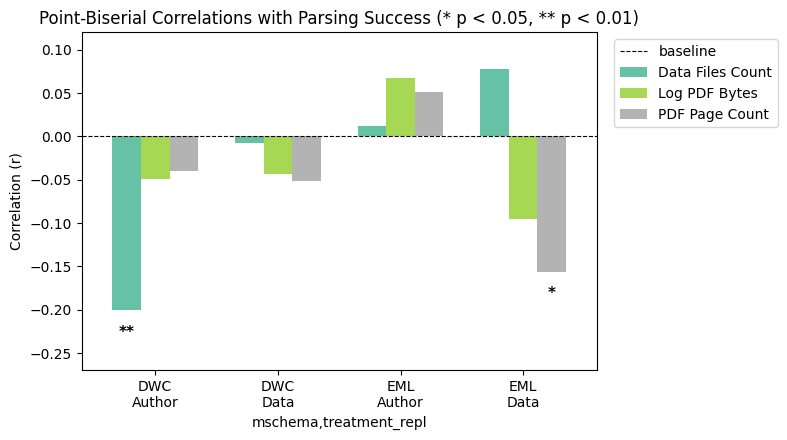

In [44]:
cols = ["nr_data_files", "log_pdf_bytes", "pdf_nr_pages"]
labels = ["baseline", "Data Files Count", "Log PDF Bytes", "PDF Page Count"]
corrs = experiment_groups_tree[cols + ["parsed_int"]].corr("pearson")["parsed_int"].unstack(level=-1).drop("parsed_int", axis=1)

ax = corrs[cols].plot(kind="bar", figsize=(8, 4.5), cmap="Set2", width=0.7)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xticklabels(["DWC\nAuthor", "DWC\nData", "EML\nAuthor", "EML\nData"], rotation=0)
ax.set_ylabel("Correlation (r)")
ax.set_ylim(-0.27, 0.12)
ax.legend(labels, bbox_to_anchor=(1.02, 1), loc="upper left")

# Compute and annotate significance stars (* p < 0.05, ** p < 0.01)
for g_idx, (name, group) in enumerate(experiment_groups_tree):
    for c_idx, col in enumerate(cols):
        r, p_val = pointbiserialr(group["parsed_int"], group[col])
        if p_val < 0.05:
            star = "**" if p_val < 0.01 else "*"
            bar_container = ax.containers[c_idx]
            bar = bar_container[g_idx]
            y_pos = bar.get_height() - 0.025 if bar.get_height() < 0 else bar.get_height() + 0.005
            ax.text(bar.get_x() + bar.get_width() / 2, y_pos, star, ha="center", va="center", fontweight="bold", fontsize=11)

plt.title("Point-Biserial Correlations with Parsing Success (* p < 0.05, ** p < 0.01)")
plt.tight_layout()
plt.show()

In [45]:
features = ["nr_data_files", "pdf_bytes", "log_pdf_bytes", "pdf_nr_pages"]
records = []

# Loop through each multi-index group (schema, treatment)
for (schema, treatment), group in experiment_groups_tree:
    for feat in features:
        r_pearson = group[feat].corr(group["parsed_int"], method="pearson")
        r_spearman = group[feat].corr(group["parsed_int"], method="spearman")
        r_pb, p_val = pointbiserialr(group["parsed_int"], group[feat])
        
        records.append({
            "schema": schema,
            "treatment": treatment,
            "feature": feat,
            "pearson_r": r_pearson,
            "spearman_rho": r_spearman,
            "point_biserial_r": r_pb,
            "p_value": p_val
        })

# Format as MultiIndex Matrix
matrix_df = pd.DataFrame(records).set_index(["schema", "treatment", "feature"])
matrix_df

pearson_r  spearman_rho  \
schema treatment           feature                                  
dwc    data-file-provider  nr_data_files  -0.200847     -0.204272   
                           pdf_bytes       0.009867     -0.031496   
                           log_pdf_bytes  -0.048940     -0.031496   
                           pdf_nr_pages   -0.039847     -0.042375   
       data-paper-provider nr_data_files  -0.007299      0.002944   
                           pdf_bytes      -0.069143     -0.000656   
                           log_pdf_bytes  -0.043839     -0.000656   
                           pdf_nr_pages   -0.051419     -0.091319   
eml    data-file-provider  nr_data_files   0.011364      0.020740   
                           pdf_bytes       0.035015      0.013645   
                           log_pdf_bytes   0.067035      0.013645   
                           pdf_nr_pages    0.051561      0.058174   
       data-paper-provider nr_data_files   0.077220      0.085106   
                           pdf_bytes      -0.016647     -0.090577   
                           log_pdf_bytes  -0.095348     -0.090577   
                           pdf_nr_pages   -0.155957     -0.157060   

                                          point_biserial_r   p_value  
schema treatment           feature                                    
dwc    data-file-provider  nr_data_files         -0.200847  0.007021  
                           pdf_bytes              0.009867  0.895702  
                           log_pdf_bytes         -0.048940  0.515318  
                           pdf_nr_pages          -0.039847  0.596399  
       data-paper-provider nr_data_files         -0.007299  0.922754  
                           pdf_bytes             -0.069143  0.357731  
                           log_pdf_bytes         -0.043839  0.560099  
                           pdf_nr_pages          -0.051419  0.494245  
eml    data-file-provider  nr_data_files          0.011364  0.879995  
                           pdf_bytes              0.035015  0.641696  
                           log_pdf_bytes          0.067035  0.372617  
                           pdf_nr_pages           0.051561  0.493051  
       data-paper-provider nr_data_files          0.077220  0.304220  
                           pdf_bytes             -0.016647  0.824959  
                           log_pdf_bytes         -0.095348  0.204219  
                           pdf_nr_pages          -0.155957  0.037094

> **Node details**

In [46]:
%%sql experiment_tree_info_nodes << 
SELECT * 
FROM experiment_constructed_tree_info_nodes
ORDER BY case_id ASC;

Running query in 'duckdb'

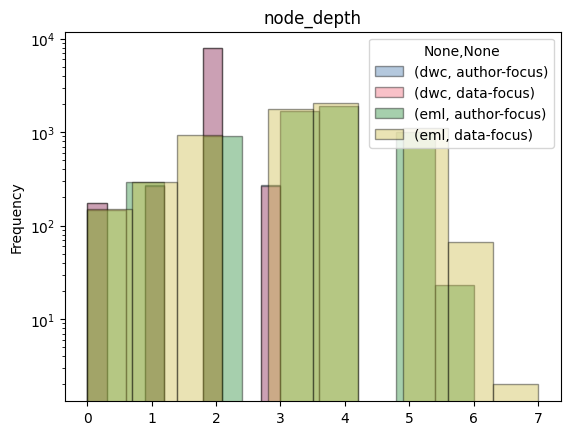

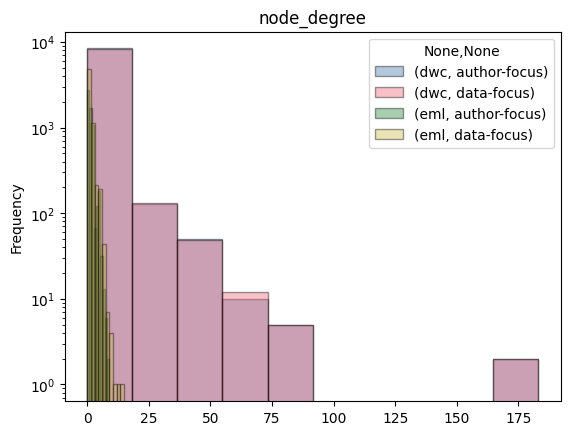

In [47]:
experiment_groups_node = experiment_tree_info_nodes.groupby(["mschema", "treatment"])

ax = None
for name,group in experiment_groups_node:
    ax = group.plot.hist(y="node_depth", alpha=0.4, ax=ax, label=name, edgecolor="k", log=True)
    ax.set_title("node_depth")
ax = None
for name,group in experiment_groups_node:
    ax = group.plot.hist(y="node_degree", alpha=0.4, ax=ax, label=name, edgecolor="k", log=True)
    ax.set_title("node_degree")

plt.show()

### Cleanup

In [48]:
try:
    del experiment_tree_info_node_dwc
    del experiment_tree_info_node_eml
    del experiment_tree_info_grand_eml
    del experiment_tree_info_grand_dwc
    del experiment_tree_info_grand
    del experiment_groups_tree
    del experiment_tree_info_nodes
    del experiment_groups_node
except Exception as e:
    print(e)

## Step 3: $COR$ metric

> **Syntactical correspondence** to a metadata schema:

$$
COR(\hat{m},s) = 1 - \frac{|{\epsilon_{s}(\hat{m})}|}{size_{+a}(\hat{m})}
$$

### Operations

In [47]:
dwc_validator = matls.get_xmlschema_validator('http://rs.tdwg.org/dwc/text/tdwg_dwc_text.xsd')
eml_validator = matls.get_xmlschema_validator('https://eml.ecoinformatics.org/eml-2.2.0/eml.xsd')

/Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/terms/' from ['http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd': Forbidden.
  return self.schema_class(
/Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/elements/1.1/' from ['http://dublincore.org/schemas/xmls/qdc/dc.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/dc.xsd': Forbidden.
  return self.schema_class(


In [48]:
class ValidationError(TypedDict):
    reason: str
    error_kind: str

class ValidationInfo(TypedDict):
    completed_ok: bool
    is_valid_xml: bool
    error_count: int
    validation_errors: list[ValidationError]

INCORRECT_VALIDATION = {
    "completed_ok": False,
    "is_valid_xml": False,
    "error_count": 0,
    "validation_errors": []
}

def validation_response_to_info(validated) -> ValidationInfo:
    if isinstance(validated, tuple):
        return {
            "completed_ok": True,
            "is_valid_xml": validated[0] and not validated[1],
            "error_count": len(validated[1]),
            "validation_errors": [
                {"reason": error.reason, "error_kind": error.__class__.__name__}
                for error in validated[1]
            ]
        }
    return INCORRECT_VALIDATION

In [49]:
def validate_xml_json(outcome_json: str, validator) -> str:
    outcome_dict = json.loads(outcome_json)
    if ('resolutions' not in outcome_dict):
        return json.dumps({'parsed': False, 'tree_info': None, 'error': "'resolutions' key is not found"})
    try:
        wc_metadata_xml = resolve_xml_content(outcome_dict)
        wc_metadata_xml_clean = cleanup_special_characters(cleanup_gap_failures(wc_metadata_xml))
        validation = validator.validate(wc_metadata_xml_clean)
        return json.dumps(validation_response_to_info(validation))
    except Exception as e:
        return json.dumps(INCORRECT_VALIDATION)

In [50]:
def validate_dwc_xml_json(outcome_json: str) -> str:
    return validate_xml_json(outcome_json, dwc_validator)

def validate_eml_xml_json(outcome_json: str) -> str:
    return validate_xml_json(outcome_json, eml_validator)

In [51]:
for f in [
    validate_dwc_xml_json, validate_eml_xml_json
]:
    try:
        conn.remove_function(f.__name__)
    except Exception as e:
        print(f"Function not found: {e}")
    conn.create_function(f.__name__, f)

Function not found: Invalid Input Error: No function by the name of 'validate_dwc_xml_json' was found in the list of registered functions
Function not found: Invalid Input Error: No function by the name of 'validate_eml_xml_json' was found in the list of registered functions


### Computing

In [52]:
%%sql dwc_schema_validation <<
SELECT 
    e.*,
    -- schema validation
    validate_dwc_xml_json(outcome_json) as validation_json,
    json_extract(validation_json, '$.completed_ok')::BOOLEAN as validation_completed_ok,
    json_extract(validation_json, '$.is_valid_xml')::BOOLEAN as validation_is_valid_xml,
    json_extract(validation_json, '$.error_count')::INT as validation_error_count,
    json_extract(validation_json, '$.validation_errors')::JSON as validation_errors_json,
    (1 - ((validation_error_count) / (e.tree_size_with_attrs))) AS metric_COR
FROM experiment_constructed_tree_info_grand e
WHERE mschema = 'dwc'
    AND validation_completed_ok
    AND NOT validation_is_valid_xml

Running query in 'duckdb'

In [53]:
%%sql eml_schema_validation <<
SELECT 
    e.*,
    -- schema validation
    validate_eml_xml_json(outcome_json) as validation_json,
    json_extract(validation_json, '$.completed_ok')::BOOLEAN as validation_completed_ok,
    json_extract(validation_json, '$.is_valid_xml')::BOOLEAN as validation_is_valid_xml,
    json_extract(validation_json, '$.error_count')::INT as validation_error_count,
    json_extract(validation_json, '$.validation_errors')::JSON as validation_errors_json,
    (1 - ((validation_error_count) / (e.tree_size_with_attrs))) AS metric_COR
FROM experiment_constructed_tree_info_grand e
WHERE mschema = 'eml'
    AND validation_completed_ok
    AND NOT validation_is_valid_xml

Running query in 'duckdb'

### Reporting

In [54]:
dwc_schema_validation.groupby(["mschema", "treatment_repl"]).describe()

case_id                                         \
                             count   mean std    min    25%    50%    75%   
mschema treatment_repl                                                      
dwc     data-file-provider     1.0  134.0 NaN  134.0  134.0  134.0  134.0   

                                  nr_data_files       ...  \
                              max         count mean  ...   
mschema treatment_repl                                ...   
dwc     data-file-provider  134.0           1.0  3.0  ...   

                           validation_error_count      metric_COR           \
                                              75%  max      count     mean   
mschema treatment_repl                                                       
dwc     data-file-provider                    2.0  2.0        1.0  0.99646   

                                                                             
                           std      min      25%      50%      75%      max  
mschema treatment_repl                                                       
dwc     data-file-provider NaN  0.99646  0.99646  0.99646  0.99646  0.99646  

[1 rows x 96 columns]

In [55]:
eml_schema_validation.groupby(["mschema", "treatment_repl"]).describe()

case_id                                          \
                              count       mean        std  min    25%   50%   
mschema treatment_repl                                                        
eml     data-file-provider    150.0  88.686667  53.070314  0.0  42.25  88.5   
        data-paper-provider   148.0  92.864865  50.983477  0.0  49.75  96.0   

                                           nr_data_files            ...  \
                                75%    max         count      mean  ...   
mschema treatment_repl                                              ...   
eml     data-file-provider   134.75  178.0         150.0  1.573333  ...   
        data-paper-provider  137.25  178.0         148.0  1.594595  ...   

                            validation_error_count      metric_COR            \
                                               75%  max      count      mean   
mschema treatment_repl                                                         
eml     data-file-provider                     3.0  8.0      150.0  0.944388   
        data-paper-provider                    3.0  5.0      148.0  0.942566   

                                                                               \
                                  std       min       25%       50%       75%   
mschema treatment_repl                                                          
eml     data-file-provider   0.022887  0.888889  0.926152  0.943757  0.963468   
        data-paper-provider  0.020239  0.905660  0.925385  0.936779  0.960784   

                                       
                                  max  
mschema treatment_repl                 
eml     data-file-provider   0.985714  
        data-paper-provider  0.984848  

[2 rows x 96 columns]

## Step 4: $STS$ metric

> **Structural tree similarity** between constructed and ground-truth metadata instances:

$$
STS({\hat{m}}, m) = 1 - \frac{APTED({\hat{m}},{m})}{size_{+a}({\hat{m}})+ size_{+a}({m})}
$$

### APTED operations

In [56]:
def xml_to_apted_tree(tree):
    if hasattr(tree, "getroot"):
        return convert_xml_to_apted(tree.getroot())
    return convert_xml_to_apted(tree)

def convert_xml_to_apted(root):
    tag = root.tag
    
    if root.attrib:
        attr_parts = [f"{{key__{k}:{{hidden_value}}}}" for k, _v in sorted(root.attrib.items())]
        node_label = f"{tag}:{':'.join(attr_parts)}"
    else:
        node_label = tag
    
    apted_children = [convert_xml_to_apted(child) for child in root]    
    return apted.helpers.Tree(node_label, *apted_children)

def apted_tree_size(tree):
    return _apted_tree_size(tree)

def _apted_tree_size(tree):
    return 1 + sum(_apted_tree_size(child) for child in tree.children)

def normalise_apted_edit_distance(raw_distance, tree1, tree2):
    max_dist = _apted_tree_size(tree1) + _apted_tree_size(tree2)
    return raw_distance / max_dist if max_dist > 0 else 0

In [57]:
class TreeEditBreakdownInfo(TypedDict):
    deletions: list
    insertions: list
    renames: list
    matches: list
    
    deletions_count: int
    insertions_count: int
    renames_count: int
    matches_count: int

def get_error_breakdown(apted_edit_mapping) -> TreeEditBreakdownInfo:
    breakdown = {
        "deletions": [],    # In Tree 1, but not in Tree 2
        "insertions": [],   # In Tree 2, but not in Tree 1
        "renames": [],      # In both, but labels/attributes differ
        "matches": []       # Identical nodes
    }
    
    for node1, node2 in apted_edit_mapping:
        if node1 is None:
            # Node exists only in generated (Tree 2) -> Hallucination
            breakdown["insertions"].append(node2.name)
        elif node2 is None:
            # Node exists only in ground truth (Tree 1) -> Omission
            breakdown["deletions"].append(node1.name)
        else:
            # Both exist; check if the label (tag + attributes) is the same
            if node1.name != node2.name:
                breakdown["renames"].append((node1.name, node2.name))
            else:
                breakdown["matches"].append(node1.name)

    return {
        **breakdown,
        "deletions_count": len(breakdown["deletions"]),
        "insertions_count": len(breakdown["insertions"]),
        "renames_count": len(breakdown["renames"]),
        "matches_count": len(breakdown["matches"]),
    }

In [58]:
class TreeJaccardInfo(TypedDict):
    node_index: float
    path_index: float

def jaccard_index(node_key: str, cons_tree: TreeInfo, gt_tree: TreeInfo) -> float:
    cons_data, gt_data = set(n[node_key] for n in cons_tree["_nodes"]), set(n[node_key] for n in gt_tree["_nodes"])
    return (len(set.intersection(cons_data,gt_data))/len(set.union(cons_data,gt_data)))

class AptedInfo(TypedDict):
    ted_distance: float | None
    norm_ted_distance: float | None
    ted_breakdown: TreeEditBreakdownInfo
    cons_apted_size: int
    gt_apted_size: int
    sts_metric: float | None
    jaccard_info: TreeJaccardInfo

def compute_apted(constructed_apted: str, ground_truth_apted: str) -> apted.APTED:
    return apted.APTED(constructed_apted, ground_truth_apted)

def compute_apted_info_json(outcome_json: str, ground_truth_tree_path: str) -> str:
    outcome_dict = json.loads(outcome_json)
    if ('resolutions' not in outcome_dict):
        return json.dumps({"failed": "not parseable data"})
    try:
        wc_metadata_xml = resolve_xml_content(outcome_dict)
        wc_metadata_xml_clean = cleanup_special_characters(cleanup_gap_failures(wc_metadata_xml))
        wc_xml_tree = parse_xml_string(wc_metadata_xml_clean)
        gt_xml_tree = parse_xml_file(grounded_path(ground_truth_tree_path))
        cons_tree_info, gt_tree_info = (get_tree_info(wc_xml_tree), get_tree_info(gt_xml_tree))
        cons_apted_tree, gt_apted_tree = (xml_to_apted_tree(wc_xml_tree), xml_to_apted_tree(gt_xml_tree))
        apted_result = compute_apted(xml_to_apted_tree(wc_xml_tree), xml_to_apted_tree(gt_xml_tree))
        apted_distance = apted_result.compute_edit_distance()
        apted_mapping = apted_result.compute_edit_mapping()
        norm_apted_distance = normalise_apted_edit_distance(apted_distance, cons_apted_tree, gt_apted_tree)
        apted_info: AptedInfo = {
            "ted_distance": apted_distance,
            "ted_breakdown": get_error_breakdown(apted_mapping),
            "cons_apted_size": apted_tree_size(cons_apted_tree),
            "gt_apted_size": apted_tree_size(gt_apted_tree),
            "norm_ted_distance": norm_apted_distance,
            "sts_metric": 1 - norm_apted_distance,
            "jaccard_info": {
                "node_index": jaccard_index("tag", cons_tree_info, gt_tree_info),
                "path_index": jaccard_index("path", cons_tree_info, gt_tree_info),
            },
        }
        return json.dumps(apted_info)
    except Exception as e:
        return json.dumps({"failed": str(e)})

In [59]:
for f in [compute_apted_info_json]:
    try:
        conn.remove_function(f.__name__)
    except Exception as e:
        print(f"Function not found: {e}")
    conn.create_function(f.__name__, f)

Function not found: Invalid Input Error: No function by the name of 'compute_apted_info_json' was found in the list of registered functions


### Computing

In [60]:
%%sql 
CREATE OR REPLACE TABLE dwc_tree_edit_distances AS (
    SELECT 
        e.*, 
        compute_apted_info_json(outcome_json, ground_truth_metadata_dwc) AS apted_info,
    FROM experiment_constructed_tree_info_grand e
    WHERE mschema = 'dwc'
);

Running query in 'duckdb'

,Count
0,358


In [61]:
%%sql
CREATE OR REPLACE TABLE eml_tree_edit_distances AS (
    SELECT 
        e.*,
        compute_apted_info_json(outcome_json, ground_truth_metadata_eml) AS apted_info,
    FROM experiment_constructed_tree_info_grand e
    WHERE mschema = 'eml'
);

Running query in 'duckdb'

,Count
0,358


### Reporting

#### DwC-T

In [62]:
%%sql dwc_sts_scores <<
SELECT 
    *,
    json_extract(apted_info, '$.sts_metric')::FLOAT AS sts_metric,
    json_extract(apted_info, '$.jaccard_info.node_index')::FLOAT AS jaccard_node_index,
    json_extract(apted_info, '$.jaccard_info.path_index')::FLOAT AS jaccard_path_index,
FROM dwc_tree_edit_distances
WHERE parsed

Running query in 'duckdb'

In [63]:
for name, group in dwc_sts_scores.groupby(["mschema", "treatment_repl"]):
    display(name)
    display(group[["sts_metric", "jaccard_node_index", "jaccard_path_index"]].describe())

('dwc', 'data-file-provider')

,sts_metric,jaccard_node_index,jaccard_path_index
count,173.000000,173.000000,173.000000
mean,0.968334,0.999277,0.957392
std,0.029327,0.009504,0.112769
min,0.833333,0.875000,0.412371
25%,0.958678,1.000000,1.000000
50%,0.980392,1.000000,1.000000
75%,0.987179,1.000000,1.000000
max,1.000000,1.000000,1.000000


('dwc', 'data-paper-provider')

,sts_metric,jaccard_node_index,jaccard_path_index
count,173.000000,173.000000,173.000000
mean,0.964429,0.997832,0.949565
std,0.034389,0.021201,0.122992
min,0.790698,0.750000,0.402062
25%,0.950980,1.000000,0.983871
50%,0.979167,1.000000,1.000000
75%,0.986111,1.000000,1.000000
max,0.994186,1.000000,1.000000


In [64]:
%%sql dwc_sts_scores_breakdown_counts <<
SELECT 
    mschema, 
    treatment_repl,
    json_extract(apted_info, '$.ted_breakdown.deletions_count')::INT AS deletions_count,
    json_extract(apted_info, '$.ted_breakdown.insertions_count')::INT AS insertions_count,
    json_extract(apted_info, '$.ted_breakdown.renames_count')::INT AS renames_count,
    json_extract(apted_info, '$.ted_breakdown.matches_count')::INT AS matches_count,
FROM dwc_tree_edit_distances
WHERE parsed

Running query in 'duckdb'

In [65]:
for name, group in dwc_sts_scores_breakdown_counts.groupby(["mschema", "treatment_repl"]):
    display(name)
    display(group.describe())

('dwc', 'data-file-provider')

,deletions_count,insertions_count,renames_count,matches_count
count,173.0,173.0,173.0,173.0
mean,0.716763,0.803468,1.693642,46.531792
std,1.696647,1.885252,1.47215,22.284247
min,0.0,0.0,0.0,11.0
25%,0.0,0.0,1.0,31.0
50%,0.0,0.0,1.0,43.0
75%,0.0,0.0,2.0,56.0
max,7.0,12.0,9.0,188.0


('dwc', 'data-paper-provider')

,deletions_count,insertions_count,renames_count,matches_count
count,173.0,173.0,173.0,173.0
mean,0.878613,1.023121,1.710983,46.410405
std,1.926635,2.294974,1.400891,21.855213
min,0.0,0.0,0.0,11.0
25%,0.0,0.0,1.0,31.0
50%,0.0,0.0,1.0,43.0
75%,0.0,1.0,2.0,56.0
max,9.0,16.0,9.0,185.0


In [66]:
%%sql
WITH dwc_deletions_and_insertions AS (
    (
        SELECT 
            mschema, 
            treatment_repl,
            de.*,
            'deletions' AS kind
        FROM dwc_tree_edit_distances,
            json_each(json_extract(apted_info, '$.ted_breakdown.deletions')) AS de
        WHERE parsed
    )
        
    UNION
    
    (
        SELECT 
            mschema, 
            treatment_repl,
            de.*,
            'insertions' AS kind
        FROM dwc_tree_edit_distances,
            json_each(json_extract(apted_info, '$.ted_breakdown.insertions')) AS de
        WHERE parsed
    )
)
SELECT 
    mschema, 
    treatment_repl,
    split("value", ':')[-3:] AS tail, 
    "kind", 
    COUNT(1)
FROM dwc_deletions_and_insertions
GROUP BY 1,2,3,4
ORDER BY 2,4,5 DESC

Running query in 'duckdb'

,mschema,treatment_repl,tail,kind,count(1)
0,dwc,data-file-provider,"[{hidden_value}}, {key__rowType, {hidden_value...",deletions,7
1,dwc,data-file-provider,"[{hidden_value}}, {key__term, {hidden_value}}""]",deletions,6
2,dwc,data-file-provider,"[""{http, //rs.tdwg.org/dwc/text/}files""]",deletions,2
3,dwc,data-file-provider,"[//rs.tdwg.org/dwc/text/}extension, {key__rowT...",deletions,2
4,dwc,data-file-provider,"[//rs.tdwg.org/dwc/text/}coreid, {key__index, ...",deletions,1
5,dwc,data-file-provider,"[""{http, //rs.tdwg.org/dwc/text/}location""]",deletions,1
6,dwc,data-file-provider,"[{hidden_value}}, {key__term, {hidden_value}}""]",insertions,13
7,dwc,data-file-provider,"[{hidden_value}}, {key__rowType, {hidden_value...",insertions,5
8,dwc,data-file-provider,"[""{http, //rs.tdwg.org/dwc/text/}files""]",insertions,2
9,dwc,data-file-provider,"[""{http, //rs.tdwg.org/dwc/text/}location""]",insertions,1


In [67]:
%%sql
WITH dwc_renames AS (
    SELECT 
        mschema, 
        treatment_repl,
        de.*,
        de."value"[0] AS "ren_source",
        de."value"[1] AS "ren_target",
        'renames' AS kind
    FROM dwc_tree_edit_distances,
        json_each(json_extract(apted_info, '$.ted_breakdown.renames')) AS de
    WHERE parsed
)
SELECT 
    mschema, 
    treatment_repl,
    split(ren_source, ':')[-4:] AS ren_source_tail,
    split(ren_target, ':')[-4:] AS ren_target_tail,
    "kind", 
    COUNT(1)
FROM dwc_renames
GROUP BY 1,2,3,4,5
ORDER BY 2,6 DESC

Running query in 'duckdb'

,mschema,treatment_repl,ren_source_tail,ren_target_tail,kind,count(1)
0,dwc,data-file-provider,"[{key__ignoreHeaderLines, {hidden_value}}, {ke...","[{key__linesTerminatedBy, {hidden_value}}, {ke...",renames,209
1,dwc,data-file-provider,"[{key__index, {hidden_value}}, {key__term, {hi...","[{key__index, {hidden_value}}, {key__term, {hi...",renames,68
2,dwc,data-file-provider,"[""{http, //rs.tdwg.org/dwc/text/}extension, {k...","[{key__linesTerminatedBy, {hidden_value}}, {ke...",renames,7
3,dwc,data-file-provider,"[""{http, //rs.tdwg.org/dwc/text/}coreid, {key_...","[{key__index, {hidden_value}}, {key__term, {hi...",renames,2
4,dwc,data-file-provider,"[""{http, //rs.tdwg.org/dwc/text/}location""]","[{key__index, {hidden_value}}, {key__term, {hi...",renames,2
5,dwc,data-file-provider,"[{key__index, {hidden_value}}, {key__term, {hi...","[""{http, //rs.tdwg.org/dwc/text/}location""]",renames,2
6,dwc,data-file-provider,"[""{http, //rs.tdwg.org/dwc/text/}archive, {key...","[""{http, //rs.tdwg.org/dwc/text/}archive""]",renames,2
7,dwc,data-file-provider,"[{key__index, {hidden_value}}, {key__term, {hi...","[""{http, //rs.tdwg.org/dwc/text/}coreid, {key_...",renames,1
8,dwc,data-paper-provider,"[{key__ignoreHeaderLines, {hidden_value}}, {ke...","[{key__linesTerminatedBy, {hidden_value}}, {ke...",renames,218
9,dwc,data-paper-provider,"[{key__index, {hidden_value}}, {key__term, {hi...","[{key__index, {hidden_value}}, {key__term, {hi...",renames,64


#### EML

In [68]:
%%sql eml_sts_scores <<
SELECT 
    *,
    json_extract(apted_info, '$.sts_metric')::FLOAT AS sts_metric,
    json_extract(apted_info, '$.jaccard_info.node_index')::FLOAT AS jaccard_node_index,
    json_extract(apted_info, '$.jaccard_info.path_index')::FLOAT AS jaccard_path_index,
FROM eml_tree_edit_distances
WHERE parsed

Running query in 'duckdb'

In [69]:
for name, group in eml_sts_scores.groupby(["mschema", "treatment_repl"]):
    display(name)
    display(group[["sts_metric", "jaccard_node_index", "jaccard_path_index"]].describe())

('eml', 'data-file-provider')

,sts_metric,jaccard_node_index,jaccard_path_index
count,150.000000,150.000000,150.000000
mean,0.230780,0.235070,0.081606
std,0.089972,0.040104,0.038189
min,0.027696,0.133333,0.012530
25%,0.167198,0.209877,0.055609
50%,0.226959,0.236257,0.075551
75%,0.281091,0.256332,0.105430
max,0.468468,0.405797,0.224138


('eml', 'data-paper-provider')

,sts_metric,jaccard_node_index,jaccard_path_index
count,147.000000,147.000000,147.000000
mean,0.222635,0.235318,0.080530
std,0.092185,0.039181,0.042021
min,0.007704,0.145161,0.002680
25%,0.167324,0.202532,0.052525
50%,0.217021,0.237113,0.074713
75%,0.283662,0.266251,0.101483
max,0.500000,0.346667,0.250000


In [70]:
%%sql eml_sts_scores_breakdown_counts <<
SELECT 
    mschema, 
    treatment_repl,
    json_extract(apted_info, '$.ted_breakdown.deletions_count')::INT AS deletions_count,
    json_extract(apted_info, '$.ted_breakdown.insertions_count')::INT AS insertions_count,
    json_extract(apted_info, '$.ted_breakdown.renames_count')::INT AS renames_count,
    json_extract(apted_info, '$.ted_breakdown.matches_count')::INT AS matches_count,
FROM eml_tree_edit_distances
WHERE parsed

Running query in 'duckdb'

In [71]:
for name, group in eml_sts_scores_breakdown_counts.groupby(["mschema", "treatment_repl"]):
    display(name)
    display(group.describe())

('eml', 'data-file-provider')

,deletions_count,insertions_count,renames_count,matches_count
count,150.0,150.0,150.0,150.0
mean,5.933333,223.613333,16.626667,19.9
std,3.490479,196.237248,9.115623,7.429986
min,2.0,10.0,2.0,8.0
25%,3.0,108.0,10.25,14.0
50%,5.0,168.5,17.0,17.0
75%,8.0,284.0,24.0,26.0
max,21.0,1637.0,37.0,51.0


('eml', 'data-paper-provider')

,deletions_count,insertions_count,renames_count,matches_count
count,147.0,147.0,147.0,147.0
mean,5.115646,275.972789,15.170068,19.748299
std,2.948222,541.971944,8.705512,6.064543
min,2.0,4.0,2.0,6.0
25%,3.0,110.0,8.0,15.0
50%,4.0,178.0,16.0,18.0
75%,7.0,288.0,21.5,25.0
max,16.0,6295.0,38.0,37.0


In [72]:
%%sql
WITH eml_deletions_and_insertions AS (
    (
        SELECT 
            mschema, 
            treatment_repl,
            de.*,
            'deletions' AS kind
        FROM eml_tree_edit_distances,
            json_each(json_extract(apted_info, '$.ted_breakdown.deletions')) AS de
        WHERE parsed
    )
        
    UNION
    
    (
        SELECT 
            mschema, 
            treatment_repl,
            de.*,
            'insertions' AS kind
        FROM eml_tree_edit_distances,
            json_each(json_extract(apted_info, '$.ted_breakdown.insertions')) AS de
        WHERE parsed
    )
)
SELECT 
    mschema, 
    treatment_repl,
    split("value", ':')[-3:] AS tail, 
    "kind", 
    COUNT(1)
FROM eml_deletions_and_insertions
GROUP BY 1,2,3,4
ORDER BY 2,4,5 DESC

Running query in 'duckdb'

,mschema,treatment_repl,tail,kind,count(1)
0,eml,data-file-provider,"[""maintenanceUpdateFrequency""]",deletions,10
1,eml,data-file-provider,"[""title""]",deletions,9
2,eml,data-file-provider,"[{hidden_value}}, {key__name, {hidden_value}}""]",deletions,8
3,eml,data-file-provider,"[""project""]",deletions,8
4,eml,data-file-provider,"[""methods""]",deletions,8
...,...,...,...,...,...
461,eml,data-paper-provider,"[""jgtiUnits, {key__uncertaintyMeasure, {hidden...",insertions,2
462,eml,data-paper-provider,"[""metadata""]",insertions,2
463,eml,data-paper-provider,"[""award""]",insertions,1
464,eml,data-paper-provider,"[""singleDateTime""]",insertions,1


In [73]:
%%sql
WITH eml_renames AS (
    SELECT 
        mschema, 
        treatment_repl,
        de.*,
        de."value"[0] AS "ren_source",
        de."value"[1] AS "ren_target",
        'renames' AS kind
    FROM eml_tree_edit_distances,
        json_each(json_extract(apted_info, '$.ted_breakdown.renames')) AS de
    WHERE parsed
)
SELECT 
    mschema, 
    treatment_repl,
    split(ren_source, ':')[-4:] AS ren_source_tail,
    split(ren_target, ':')[-4:] AS ren_target_tail,
    "kind", 
    COUNT(1)
FROM eml_renames
GROUP BY 1,2,3,4,5
ORDER BY 2,6 DESC

Running query in 'duckdb'

,mschema,treatment_repl,ren_source_tail,ren_target_tail,kind,count(1)
0,eml,data-file-provider,"[""para""]","[""givenName""]",renames,167
1,eml,data-file-provider,"[""description""]","[""individualName""]",renames,152
2,eml,data-file-provider,"[""title""]","[""alternateIdentifier""]",renames,146
3,eml,data-file-provider,"[{hidden_value}}, {key__{http, //www.w3.org/XM...","[{hidden_value}}, {key__{http, //www.w3.org/XM...",renames,78
4,eml,data-file-provider,"[""funding""]","[""abstract""]",renames,70
...,...,...,...,...,...,...
1134,eml,data-paper-provider,"[""maintenanceUpdateFrequency""]","[""objectName""]",renames,1
1135,eml,data-paper-provider,"[""{https, //example.org/eml/custom-provenance}...","[""surName""]",renames,1
1136,eml,data-paper-provider,"[""recordBasis""]","[""citation""]",renames,1
1137,eml,data-paper-provider,"[""methods""]","[""associatedParty""]",renames,1


## Step 5: $SVS_{text}$ metric

> **Semantic value similarity** _for **text**_ contents of nodes between constructed and ground-truth metadata instances:

$$
    \phi=text 
    \mid 
    SVS_{\phi}(\hat{m},m)=1-\frac{
        \sum_{(\hat{n},n)~\in~{CN(\hat{m}, m)}}{
            \cos^{-1}(S_{C}(\phi(\hat{n}), \phi(n)))
        }
    }{
        \pi\cdot|CN(\hat{m}, m)|
    }
$$

### Operations

In [33]:
if COS_SIMILARITY_READY:
    sentence_transformer_model = SentenceTransformer('all-MiniLM-L6-v2')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [34]:
def compute_cos_similarity(v1: str, v2:str) -> float | None:
    if v1 == v2:
        return 1
    if ("not-derived-" in v1) or ("not-derived-" in v2):
        return -1
    if not v1 or not v2:
        return None

    emb1 = sentence_transformer_model.encode(v1).reshape(1,-1)
    emb2 = sentence_transformer_model.encode(v2).reshape(1,-1)

    return cosine_similarity(emb1, emb2)[0][0].item()

In [35]:
for f in [compute_cos_similarity]:
    try:
        conn.remove_function(f.__name__)
    except Exception as e:
        print(f"Function not found: {e}")
    conn.create_function(f.__name__, f)

Function not found: Invalid Input Error: No function by the name of 'compute_cos_similarity' was found in the list of registered functions


### Computing

#### Data preparation

In [459]:
%%sql
-- dwc x data-file-provider : text
CREATE 
    OR REPLACE
    TABLE 
-- IF NOT EXISTS
    dwc_data_file_provider_cons_gt_nodes_with_text AS (
    WITH constructed_nodes AS (
        SELECT  *
        FROM experiment_constructed_tree_info_nodes AS c
        WHERE c.mschema = 'dwc'
            AND c.treatment_repl = 'data-file-provider'
            AND c.node_has_text
    ), ground_truth_nodes AS (
        SELECT  *
        FROM experiment_gt_tree_info_nodes AS g
        WHERE g.mschema = 'dwc'
            AND g.treatment_repl = 'data-file-provider'
            AND g.gt_node_has_text
    )
    SELECT 
        c.fullkey, c.path, c.case_id, c.mschema, c.treatment_repl, c.node_path, c.node_tag, c.node_text, g.gt_node_text,
        compute_cos_similarity(c.node_text, g.gt_node_text) AS cos_sim_text
    FROM constructed_nodes AS c
        JOIN ground_truth_nodes AS g
            ON  c.node_path = g.gt_node_path         -- co-present nodes
            AND c.case_id = g.case_id                -- in the same case
            AND c.mschema = g.mschema                -- for the same metadata
            AND c.treatment_repl = g.treatment_repl  -- with the same information provider 
            AND c.node_has_text = g.gt_node_has_text -- both have text
);

Running query in 'duckdb'

,Count
0,267


In [460]:
%%sql
-- dwc x data-paper-provider : text
CREATE 
    OR REPLACE
    TABLE 
-- IF NOT EXISTS
    dwc_data_paper_provider_cons_gt_nodes_with_text AS (
    WITH constructed_nodes AS (
        SELECT  *
        FROM experiment_constructed_tree_info_nodes AS c
        WHERE c.mschema = 'dwc'
            AND c.treatment_repl = 'data-paper-provider'
            AND c.node_has_text
    ), ground_truth_nodes AS (
        SELECT  *
        FROM experiment_gt_tree_info_nodes AS g
        WHERE g.mschema = 'dwc'
            AND g.treatment_repl = 'data-paper-provider'
            AND g.gt_node_has_text
    )
    SELECT 
        c.fullkey, c.path, c.case_id, c.mschema, c.treatment_repl, c.node_path, c.node_tag, c.node_text, g.gt_node_text,
        compute_cos_similarity(c.node_text, g.gt_node_text) AS cos_sim_text
    FROM constructed_nodes AS c
        JOIN ground_truth_nodes AS g
            ON  c.node_path = g.gt_node_path         -- co-present nodes
            AND c.case_id = g.case_id                -- in the same case
            AND c.mschema = g.mschema                -- for the same metadata
            AND c.treatment_repl = g.treatment_repl  -- with the same information provider 
            AND c.node_has_text = g.gt_node_has_text -- both have text
);

Running query in 'duckdb'

,Count
0,270


In [461]:
%%sql
-- eml x data-file-provider : text
CREATE 
    OR REPLACE
    TABLE 
-- IF NOT EXISTS
    eml_data_file_provider_cons_gt_nodes_with_text_pairs AS (
    WITH constructed_nodes AS (
        SELECT  *
        FROM experiment_constructed_tree_info_nodes AS c
        WHERE c.mschema = 'eml'
            AND c.treatment_repl = 'data-file-provider'
            AND c.node_has_text
    ), ground_truth_nodes AS (
        SELECT  *
        FROM experiment_gt_tree_info_nodes AS g
        WHERE g.mschema = 'eml'
            AND g.treatment_repl = 'data-file-provider'
            AND g.gt_node_has_text
    )
    SELECT c.path, c.case_id, c.mschema, c.treatment_repl, c.node_path, c.node_tag, c.node_text, g.gt_node_text
    FROM constructed_nodes AS c
    JOIN ground_truth_nodes AS g
        ON  c.node_path = g.gt_node_path         -- co-present nodes
        AND c.case_id = g.case_id                -- in the same case
        AND c.mschema = g.mschema                -- for the same metadata
        AND c.treatment_repl = g.treatment_repl  -- with the same information provider 
        AND c.node_has_text = g.gt_node_has_text -- both have text
);
CREATE
    -- OR REPLACE
    TABLE
IF NOT EXISTS
    eml_data_file_provider_cons_gt_nodes_with_text AS (
    SELECT *, compute_cos_similarity(node_text, gt_node_text) AS cos_sim_text
    FROM eml_data_file_provider_cons_gt_nodes_with_text_pairs
);

Running query in 'duckdb'

,Count


In [462]:
%%sql
-- eml x data-paper-provider : text
CREATE 
    OR REPLACE
    TABLE 
-- IF NOT EXISTS
    eml_data_paper_provider_cons_gt_nodes_with_text_pairs AS (
    WITH constructed_nodes AS (
        SELECT  *
        FROM experiment_constructed_tree_info_nodes AS c
        WHERE c.mschema = 'eml'
            AND c.treatment_repl = 'data-paper-provider'
            AND c.node_has_text
    ), ground_truth_nodes AS (
        SELECT  *
        FROM experiment_gt_tree_info_nodes AS g
        WHERE g.mschema = 'eml'
            AND g.treatment_repl = 'data-paper-provider'
            AND g.gt_node_has_text
    )
    SELECT c.path, c.case_id, c.mschema, c.treatment_repl, c.node_path, c.node_tag, c.node_text, g.gt_node_text
    FROM constructed_nodes AS c
    JOIN ground_truth_nodes AS g
        ON  c.node_path = g.gt_node_path         -- co-present nodes
        AND c.case_id = g.case_id                -- in the same case
        AND c.mschema = g.mschema                -- for the same metadata
        AND c.treatment_repl = g.treatment_repl  -- with the same information provider 
        AND c.node_has_text = g.gt_node_has_text -- both have text
);
CREATE
    -- OR REPLACE
    TABLE
IF NOT EXISTS
    eml_data_paper_provider_cons_gt_nodes_with_text AS (
    SELECT *, compute_cos_similarity(node_text, gt_node_text) AS cos_sim_text
    FROM eml_data_paper_provider_cons_gt_nodes_with_text_pairs
);

Running query in 'duckdb'

,Count


In [463]:
%%sql
SELECT 
    (SELECT COUNT(1) FROM dwc_data_file_provider_cons_gt_nodes_with_text) AS count_dwc_file_attrs,
    (SELECT COUNT(1) FROM dwc_data_paper_provider_cons_gt_nodes_with_text) AS count_dwc_paper_attrs,
    (SELECT COUNT(1) FROM eml_data_file_provider_cons_gt_nodes_with_text) AS count_eml_file_attrs,
    (SELECT COUNT(1) FROM eml_data_paper_provider_cons_gt_nodes_with_text) AS count_eml_paper_attrs,

Running query in 'duckdb'

,count_dwc_file_attrs,count_dwc_paper_attrs,count_eml_file_attrs,count_eml_paper_attrs
0,267,270,864,834


#### Computing similarity metrics

In [464]:
%%sql dwc_data_file_svs_text_metric <<
SELECT 
    1 - (
        SUM(acos(cos_sim_text::DECIMAL))
        / (pi() * COUNT(1))
    ) AS svs_text
FROM dwc_data_file_provider_cons_gt_nodes_with_text
GROUP BY case_id;

Running query in 'duckdb'

In [465]:
%%sql dwc_data_paper_svs_text_metric <<
SELECT 
    1 - (
        SUM(acos(cos_sim_text::DECIMAL))
        / (pi() * COUNT(1))
    ) AS svs_text
FROM dwc_data_paper_provider_cons_gt_nodes_with_text
GROUP BY case_id;

Running query in 'duckdb'

In [466]:
%%sql eml_data_file_svs_text_metric <<
SELECT 
    1 - (
        SUM(acos(cos_sim_text::DECIMAL))
        / (pi() * COUNT(1))
    ) AS svs_text
FROM eml_data_file_provider_cons_gt_nodes_with_text
GROUP BY case_id;

Running query in 'duckdb'

In [467]:
%%sql eml_data_paper_svs_text_metric <<
SELECT 
    1 - (
        SUM(acos(cos_sim_text::DECIMAL))
        / (pi() * COUNT(1))
    ) AS svs_text
FROM eml_data_paper_provider_cons_gt_nodes_with_text
GROUP BY case_id;

Running query in 'duckdb'

### Reporting

#### Metric Values

##### DwC-T

In [468]:
display(dwc_data_file_svs_text_metric.describe())

,svs_text
count,174.000000
mean,0.956888
std,0.094137
min,0.683470
25%,1.000000
50%,1.000000
75%,1.000000
max,1.000000


In [469]:
display(dwc_data_paper_svs_text_metric.describe())

,svs_text
count,174.000000
mean,0.945152
std,0.106787
min,0.683470
25%,1.000000
50%,1.000000
75%,1.000000
max,1.000000


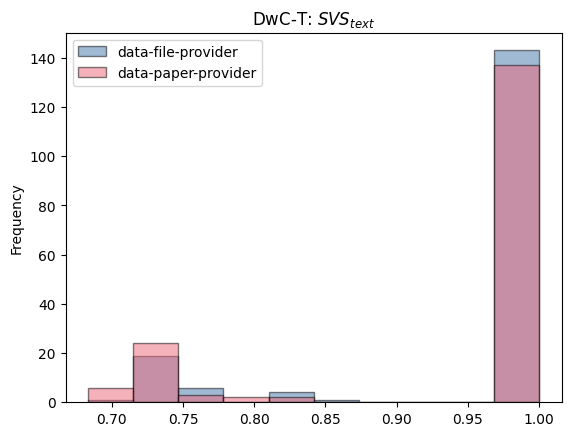

In [535]:
ax = dwc_data_file_svs_text_metric["svs_text"].plot.hist(alpha=0.5, edgecolor="k", label="data-file-provider")
ax = dwc_data_paper_svs_text_metric["svs_text"].plot.hist(alpha=0.5, edgecolor="k", label="data-paper-provider", ax = ax)
ax.set_title("DwC-T: $SVS_{text}$")
ax.legend()
plt.show()

##### EML

In [471]:
display(eml_data_file_svs_text_metric.describe())

,svs_text
count,150.000000
mean,0.308722
std,0.218816
min,0.000000
25%,0.159867
50%,0.282291
75%,0.422044
max,1.000000


In [472]:
display(eml_data_paper_svs_text_metric.describe())

,svs_text
count,148.000000
mean,0.432449
std,0.207761
min,0.000000
25%,0.316844
50%,0.444125
75%,0.581813
max,1.000000


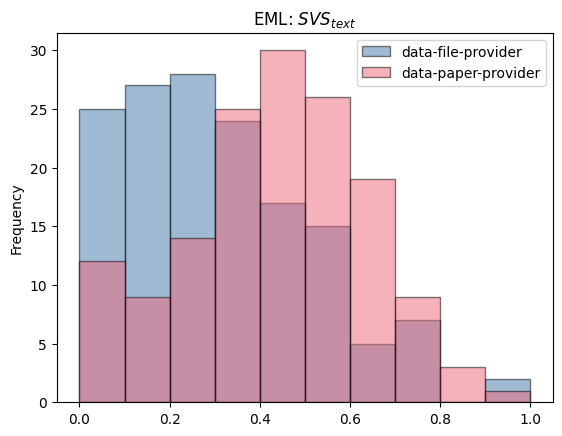

In [536]:
ax = eml_data_file_svs_text_metric["svs_text"].plot.hist(alpha=0.5, edgecolor="k", label="data-file-provider")
ax = eml_data_paper_svs_text_metric["svs_text"].plot.hist(alpha=0.5, edgecolor="k", label="data-paper-provider", ax = ax)
ax.set_title("EML: $SVS_{text}$")
ax.legend()
plt.show()

#### Support

##### DwC-T

In DwC-T, all text values are from the `<location>` nodes.

> **per case**

In [474]:
%%sql
-- dwc-t X data-file-provider
SELECT (
    SELECT COUNT(1) FROM dwc_data_file_provider_cons_gt_nodes_with_text WHERE cos_sim_text = 1.0
) / (
    SELECT COUNT(1) FROM dwc_data_file_provider_cons_gt_nodes_with_text
) * 100 AS percent_matched_exactly;

Running query in 'duckdb'

,percent_matched_exactly
0,76.404494


In [475]:
%%sql dwc_data_file_inspect_text <<
SELECT cos_sim_text
FROM dwc_data_file_provider_cons_gt_nodes_with_text

Running query in 'duckdb'

(267, 1)

(204, 1)

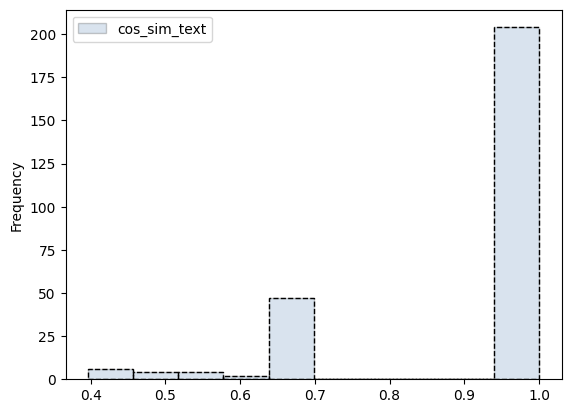

In [476]:
dwc_data_file_inspect_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=False)
dwc_data_file_inspect_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
display(dwc_data_file_inspect_text.shape)
display(dwc_data_file_inspect_text[dwc_data_file_inspect_text["cos_sim_text"] == 1.0].shape)

In [477]:
%%sql
-- dwc-t X data-paper-provider
SELECT (
    SELECT COUNT(1) FROM dwc_data_paper_provider_cons_gt_nodes_with_text WHERE cos_sim_text = 1.0
) / (
    SELECT COUNT(1) FROM dwc_data_paper_provider_cons_gt_nodes_with_text
) * 100 AS percent_matched_exactly;

Running query in 'duckdb'

,percent_matched_exactly
0,70.0


In [478]:
%%sql dwc_data_paper_inspect_text <<
SELECT cos_sim_text
FROM dwc_data_paper_provider_cons_gt_nodes_with_text

Running query in 'duckdb'

(270, 1)

(189, 1)

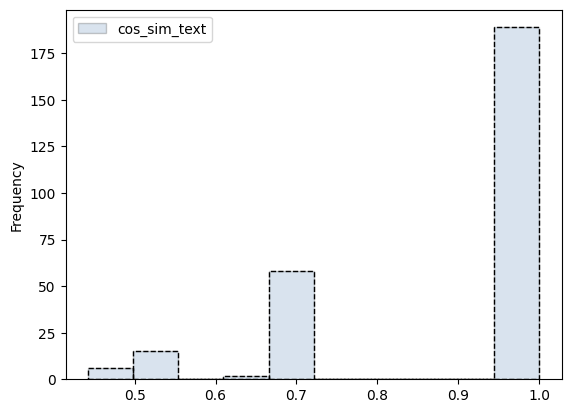

In [479]:
dwc_data_paper_inspect_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=False)
dwc_data_paper_inspect_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
display(dwc_data_paper_inspect_text.shape)
display(dwc_data_paper_inspect_text[dwc_data_paper_inspect_text["cos_sim_text"] == 1.0].shape)

> **correlation between providers** 

In [480]:
print("-- Welch's t-test: --")
display(ttest_ind(
        dwc_data_paper_inspect_text["cos_sim_text"],
        dwc_data_paper_inspect_text["cos_sim_text"],
        equal_var=False
))
print("-- Cohen's d effect size: --")
display(cohen_d(
        dwc_data_paper_inspect_text["cos_sim_text"],
        dwc_data_paper_inspect_text["cos_sim_text"],
))

-- Welch's t-test: --


TtestResult(statistic=np.float64(0.0), pvalue=np.float64(1.0), df=np.float64(538.0))

-- Cohen's d effect size: --


np.float64(0.0)

> **correlation between results and number of data files**

In [481]:
%%sql dwc_data_file_inspect_text_nr_data_files <<
SELECT d.case_id, cos_sim_text, nr_data_files
FROM dwc_data_file_provider_cons_gt_nodes_with_text AS d
JOIN (
    SELECT case_id, MAX(nr_data_files) AS nr_data_files
    FROM prep_gbif_cases
    GROUP BY case_id
) AS c 
    ON d.case_id = c.case_id

Running query in 'duckdb'

In [482]:
print("-- Pearson's r: --")
display(pearsonr(
    dwc_data_file_inspect_text_nr_data_files["cos_sim_text"],
    dwc_data_file_inspect_text_nr_data_files["nr_data_files"],
))
print("-- Cohen's d effect size: --")
display(cohen_d(
    dwc_data_file_inspect_text_nr_data_files["cos_sim_text"],
    dwc_data_file_inspect_text_nr_data_files["nr_data_files"],
))

-- Pearson's r: --


PearsonRResult(statistic=np.float64(-0.4605443688757247), pvalue=np.float64(2.0096870449859787e-15))

-- Cohen's d effect size: --


np.float64(-1.6518499247340301)

In [483]:
%%sql dwc_data_paper_inspect_text_nr_data_files <<
SELECT d.case_id, cos_sim_text, nr_data_files
FROM dwc_data_paper_provider_cons_gt_nodes_with_text AS d
JOIN (
    SELECT case_id, MAX(nr_data_files) AS nr_data_files
    FROM prep_gbif_cases
    GROUP BY case_id
) AS c 
    ON d.case_id = c.case_id

Running query in 'duckdb'

In [484]:
print("-- Pearson's r: --")
display(pearsonr(
    dwc_data_paper_inspect_text_nr_data_files["cos_sim_text"],
    dwc_data_paper_inspect_text_nr_data_files["nr_data_files"],
))
print("-- Cohen's d effect size: --")
display(cohen_d(
    dwc_data_paper_inspect_text_nr_data_files["cos_sim_text"],
    dwc_data_paper_inspect_text_nr_data_files["nr_data_files"],
))

-- Pearson's r: --


PearsonRResult(statistic=np.float64(-0.5495099288907679), pvalue=np.float64(1.0561220138312738e-22))

-- Cohen's d effect size: --


np.float64(-1.7296364374033881)

##### EML

In EML, text values communicate more diverse information than DwC-T.

> **per case**

In [485]:
%%sql eml_data_file_inspect_text <<
SELECT cos_sim_text
FROM eml_data_file_provider_cons_gt_nodes_with_text

Running query in 'duckdb'

(864, 1)

(47, 1)

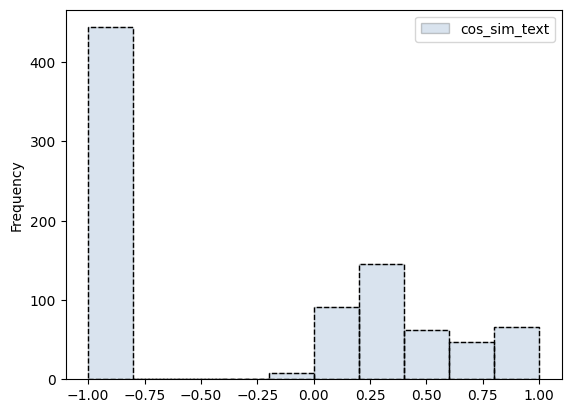

In [486]:
eml_data_file_inspect_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=False)
eml_data_file_inspect_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
display(eml_data_file_inspect_text.shape)
display(eml_data_file_inspect_text[eml_data_file_inspect_text["cos_sim_text"] == 1.0].shape)

In [487]:
%%sql eml_data_paper_inspect_text <<
SELECT cos_sim_text
FROM eml_data_paper_provider_cons_gt_nodes_with_text

Running query in 'duckdb'

(834, 1)

(80, 1)

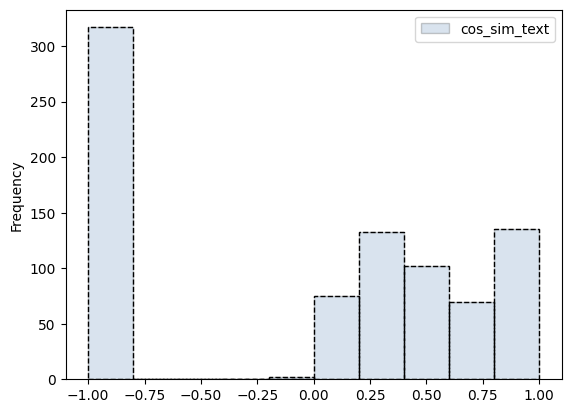

In [488]:
eml_data_paper_inspect_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=False)
eml_data_paper_inspect_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
display(eml_data_paper_inspect_text.shape)
display(eml_data_paper_inspect_text[eml_data_paper_inspect_text["cos_sim_text"] == 1.0].shape)

> **true positive and false positive text assignments by massi**

In [489]:
%%sql
WITH constructed_nodes AS (
    SELECT  *
    FROM experiment_constructed_tree_info_nodes AS c
    WHERE c.mschema = 'eml'
        AND c.node_has_text
), ground_truth_nodes AS (
    SELECT  *
    FROM experiment_gt_tree_info_nodes AS g
    WHERE g.mschema = 'eml'
)
SELECT 
    c.treatment_repl,
    node_has_text, 
    gt_node_has_text, 
    COUNT(1) AS constructed_assigned_text, 
    (SELECT COUNT(1) FROM constructed_nodes WHERE c.treatment_repl = treatment_repl) AS total_constructed_nodes,
    constructed_assigned_text / (SELECT COUNT(1) FROM constructed_nodes  WHERE c.treatment_repl = treatment_repl) * 100 AS assigned_percentage
FROM constructed_nodes AS c
JOIN ground_truth_nodes AS g
    ON  c.node_path = g.gt_node_path         -- co-present nodes
    AND c.case_id = g.case_id                -- in the same case
    AND c.mschema = g.mschema                -- for the same metadata
    AND c.treatment_repl = g.treatment_repl  -- with the same information provider 
    AND c.node_has_text                      -- at least assigned by massi
GROUP BY 1,2,3
ORDER BY 1,2,3

Running query in 'duckdb'

,treatment_repl,node_has_text,gt_node_has_text,constructed_assigned_text,total_constructed_nodes,assigned_percentage
0,data-file-provider,True,False,212,2936,7.220708
1,data-file-provider,True,True,864,2936,29.427793
2,data-paper-provider,True,False,219,2732,8.016105
3,data-paper-provider,True,True,834,2732,30.527086


In [490]:
%%sql
SELECT node_tag, COUNT(1)
FROM eml_data_file_provider_cons_gt_nodes_with_text
GROUP BY 1

Running query in 'duckdb'

,node_tag,count(1)
0,"""givenName""",2
1,"""userId""",19
2,"""url""",1
3,"""para""",257
4,"""geographicDescription""",1
5,"""maintenanceUpdateFrequency""",145
6,"""role""",67
7,"""title""",251
8,"""electronicMailAddress""",1
9,"""calendarDate""",2


In [491]:
%%sql
SELECT node_tag, COUNT(1)
FROM eml_data_paper_provider_cons_gt_nodes_with_text
GROUP BY 1

Running query in 'duckdb'

,node_tag,count(1)
0,"""givenName""",2
1,"""userId""",17
2,"""para""",253
3,"""descriptorValue""",11
4,"""surName""",96
5,"""geographicDescription""",2
6,"""maintenanceUpdateFrequency""",142
7,"""role""",63
8,"""title""",247
9,"""electronicMailAddress""",1


> **comparison across treatments**

In [492]:
print("-- Welch's t-test: --")
display(ttest_ind(
    eml_data_file_inspect_text["cos_sim_text"],
    eml_data_paper_inspect_text["cos_sim_text"],
    equal_var=False
))
print("-- Welch's u-test: --")
display(mannwhitneyu(
    eml_data_file_inspect_text["cos_sim_text"],
    eml_data_paper_inspect_text["cos_sim_text"],
    alternative="two-sided"
))
print("-- Cohen's d effect size: --")
display(cohen_d(
    eml_data_file_inspect_text["cos_sim_text"],
    eml_data_paper_inspect_text["cos_sim_text"],
))

-- Welch's t-test: --


TtestResult(statistic=np.float64(-6.928530781489268), pvalue=np.float64(6.033520091734789e-12), df=np.float64(1683.0510057723984))

-- Welch's u-test: --


MannwhitneyuResult(statistic=np.float64(290686.5), pvalue=np.float64(4.999914467982981e-13))

-- Cohen's d effect size: --


np.float64(-0.33664523278476455)

## Step 6: $SVS_{attr}$ metric

> **Semantic value similarity** _for attribute_ contents of nodes between constructed and ground-truth metadata instances:

$$
    \phi=attr 
    \mid 
    SVS_{\phi}(\hat{m},m)=1-\frac{
        \sum_{(\hat{n},n)~\in~{CN(\hat{m}, m)}}{
            \cos^{-1}(S_{C}(\phi(\hat{n}), \phi(n)))
        }
    }{
        \pi\cdot|CN(\hat{m}, m)|
    }
$$

### Operations

### Computing

#### Data preparation

In [600]:
%%sql
-- dwc x data-file-provider : text
CREATE 
    -- OR REPLACE
    TABLE 
IF NOT EXISTS
    dwc_data_file_provider_cons_gt_nodes_with_attributes AS (
    WITH constructed_nodes AS (
        SELECT  *
        FROM experiment_constructed_tree_info_nodes AS c
        WHERE c.mschema = 'dwc'
            AND c.treatment_repl = 'data-file-provider'
            AND c.node_has_attributes
    ), ground_truth_nodes AS (
        SELECT  *
        FROM experiment_gt_tree_info_nodes AS g
        WHERE g.mschema = 'dwc'
            AND g.treatment_repl = 'data-file-provider'
            AND g.gt_node_has_attributes
    )
    SELECT 
        c.fullkey, c.path, c.case_id, c.mschema, c.treatment_repl, c.node_path, c.node_tag, c.node_attributes, g.gt_node_attributes,
        compute_cos_similarity(c.node_attributes, g.gt_node_attributes) AS cos_sim_attributes
    FROM constructed_nodes AS c
        JOIN ground_truth_nodes AS g
            ON  c.node_path = g.gt_node_path                      -- co-present nodes
            AND c.case_id = g.case_id                             -- in the same case
            AND c.mschema = g.mschema                             -- for the same metadata
            AND c.treatment_repl = g.treatment_repl               -- with the same information provider 
            AND c.node_has_attributes = g.gt_node_has_attributes  -- both have attributes
);

Running query in 'duckdb'

,Count


In [596]:
%%sql
-- dwc x data-paper-provider : text
CREATE 
    -- OR REPLACE
    TABLE 
IF NOT EXISTS
    dwc_data_paper_provider_cons_gt_nodes_with_attributes AS (
    WITH constructed_nodes AS (
        SELECT  *
        FROM experiment_constructed_tree_info_nodes AS c
        WHERE c.mschema = 'dwc'
            AND c.treatment_repl = 'data-paper-provider'
            AND c.node_has_attributes
    ), ground_truth_nodes AS (
        SELECT  *
        FROM experiment_gt_tree_info_nodes AS g
        WHERE g.mschema = 'dwc'
            AND g.treatment_repl = 'data-paper-provider'
            AND g.gt_node_has_attributes
    )
    SELECT 
        c.fullkey, c.path, c.case_id, c.mschema, c.treatment_repl, c.node_path, c.node_tag, c.node_attributes, g.gt_node_attributes,
        compute_cos_similarity(c.node_attributes, g.gt_node_attributes) AS cos_sim_attributes
    FROM constructed_nodes AS c
        JOIN ground_truth_nodes AS g
            ON  c.node_path = g.gt_node_path                      -- co-present nodes
            AND c.case_id = g.case_id                             -- in the same case
            AND c.mschema = g.mschema                             -- for the same metadata
            AND c.treatment_repl = g.treatment_repl               -- with the same information provider 
            AND c.node_has_attributes = g.gt_node_has_attributes  -- both have attributes
);

Running query in 'duckdb'

,Count


In [597]:
%%sql
-- eml x data-file-provider : text
CREATE 
    -- OR REPLACE
    TABLE 
IF NOT EXISTS
    eml_data_file_provider_cons_gt_nodes_with_attributes AS (
    WITH constructed_nodes AS (
        SELECT  *
        FROM experiment_constructed_tree_info_nodes AS c
        WHERE c.mschema = 'eml'
            AND c.treatment_repl = 'data-file-provider'
            AND c.node_has_attributes
    ), ground_truth_nodes AS (
        SELECT  *
        FROM experiment_gt_tree_info_nodes AS g
        WHERE g.mschema = 'eml'
            AND g.treatment_repl = 'data-file-provider'
            AND g.gt_node_has_attributes
    )
    SELECT 
        c.fullkey, c.path, c.case_id, c.mschema, c.treatment_repl, c.node_path, c.node_tag, c.node_attributes, g.gt_node_attributes,
        compute_cos_similarity(c.node_attributes, g.gt_node_attributes) AS cos_sim_attributes
    FROM constructed_nodes AS c
        JOIN ground_truth_nodes AS g
            ON  c.node_path = g.gt_node_path                      -- co-present nodes
            AND c.case_id = g.case_id                             -- in the same case
            AND c.mschema = g.mschema                             -- for the same metadata
            AND c.treatment_repl = g.treatment_repl               -- with the same information provider 
            AND c.node_has_attributes = g.gt_node_has_attributes  -- both have attributes
);

Running query in 'duckdb'

,Count


In [598]:
%%sql
-- eml x data-paper-provider : text
CREATE 
    -- OR REPLACE
    TABLE 
IF NOT EXISTS
    eml_data_paper_provider_cons_gt_nodes_with_attributes AS (
    WITH constructed_nodes AS (
        SELECT  *
        FROM experiment_constructed_tree_info_nodes AS c
        WHERE c.mschema = 'eml'
            AND c.treatment_repl = 'data-paper-provider'
            AND c.node_has_attributes
    ), ground_truth_nodes AS (
        SELECT  *
        FROM experiment_gt_tree_info_nodes AS g
        WHERE g.mschema = 'eml'
            AND g.treatment_repl = 'data-paper-provider'
            AND g.gt_node_has_attributes
    )
    SELECT 
        c.fullkey, c.path, c.case_id, c.mschema, c.treatment_repl, c.node_path, c.node_tag, c.node_attributes, g.gt_node_attributes,
        compute_cos_similarity(c.node_attributes, g.gt_node_attributes) AS cos_sim_attributes
    FROM constructed_nodes AS c
        JOIN ground_truth_nodes AS g
            ON  c.node_path = g.gt_node_path                      -- co-present nodes
            AND c.case_id = g.case_id                             -- in the same case
            AND c.mschema = g.mschema                             -- for the same metadata
            AND c.treatment_repl = g.treatment_repl               -- with the same information provider 
            AND c.node_has_attributes = g.gt_node_has_attributes  -- both have attributes
);

Running query in 'duckdb'

,Count


In [599]:
%%sql
SELECT 
    (SELECT COUNT(1) FROM dwc_data_file_provider_cons_gt_nodes_with_attributes) AS count_dwc_file_attrs,
    (SELECT COUNT(1) FROM dwc_data_paper_provider_cons_gt_nodes_with_attributes) AS count_dwc_paper_attrs,
    (SELECT COUNT(1) FROM eml_data_file_provider_cons_gt_nodes_with_attributes) AS count_eml_file_attrs,
    (SELECT COUNT(1) FROM eml_data_paper_provider_cons_gt_nodes_with_attributes) AS count_eml_paper_attrs,

Running query in 'duckdb'

,count_dwc_file_attrs,count_dwc_paper_attrs,count_eml_file_attrs,count_eml_paper_attrs
0,7746,7711,180,176


##### Spread per attribute key

In [611]:
%%sql
CREATE 
    -- OR REPLACE
    TABLE 
IF NOT EXISTS
    dwc_data_file_provider_cons_gt_nodes_with_attributes_spread AS (
SELECT 
    *, 
    ja.key AS node_attr_key, 
    ja.value AS node_attr_value,
    json_extract(s.gt_node_attributes::JSON, node_attr_key) AS gt_node_attr_value,
    compute_cos_similarity(node_attr_value, gt_node_attr_value) AS cos_sim_attribute_key_pair
FROM dwc_data_file_provider_cons_gt_nodes_with_attributes AS s,
    json_each(s.node_attributes) AS ja
)

Running query in 'duckdb'

,Count


In [612]:
%%sql
CREATE 
    -- OR REPLACE
    TABLE 
IF NOT EXISTS
    dwc_data_paper_provider_cons_gt_nodes_with_attributes_spread AS (
SELECT 
    *, 
    ja.key AS node_attr_key, 
    ja.value AS node_attr_value,
    json_extract(s.gt_node_attributes::JSON, node_attr_key) AS gt_node_attr_value,
    compute_cos_similarity(node_attr_value, gt_node_attr_value) AS cos_sim_attribute_key_pair
FROM dwc_data_paper_provider_cons_gt_nodes_with_attributes AS s,
    json_each(s.node_attributes) AS ja
)

Running query in 'duckdb'

,Count


In [613]:
%%sql
CREATE 
    -- OR REPLACE
    TABLE 
IF NOT EXISTS
    eml_data_file_provider_cons_gt_nodes_with_attributes_spread AS (
SELECT 
    *, 
    ja.key AS node_attr_key, 
    ja.value AS node_attr_value,
    json_extract(s.gt_node_attributes::JSON, node_attr_key) AS gt_node_attr_value,
    compute_cos_similarity(node_attr_value, gt_node_attr_value) AS cos_sim_attribute_key_pair
FROM eml_data_file_provider_cons_gt_nodes_with_attributes AS s,
    json_each(s.node_attributes) AS ja
)

Running query in 'duckdb'

,Count


In [614]:
%%sql
CREATE 
    -- OR REPLACE
    TABLE 
IF NOT EXISTS
    eml_data_paper_provider_cons_gt_nodes_with_attributes_spread AS (
SELECT 
    *, 
    ja.key AS node_attr_key, 
    ja.value AS node_attr_value,
    json_extract(s.gt_node_attributes::JSON, node_attr_key) AS gt_node_attr_value,
    compute_cos_similarity(node_attr_value, gt_node_attr_value) AS cos_sim_attribute_key_pair
FROM eml_data_paper_provider_cons_gt_nodes_with_attributes AS s,
    json_each(s.node_attributes) AS ja
)

Running query in 'duckdb'

,Count


In [615]:
%%sql
SELECT 
    (SELECT COUNT(1) FROM dwc_data_file_provider_cons_gt_nodes_with_attributes_spread) AS count_dwc_file_attrs_pairs,
    (SELECT COUNT(1) FROM dwc_data_paper_provider_cons_gt_nodes_with_attributes_spread) AS count_dwc_paper_attrs_pairs,
    (SELECT COUNT(1) FROM eml_data_file_provider_cons_gt_nodes_with_attributes_spread) AS count_eml_file_attrs_pairs,
    (SELECT COUNT(1) FROM eml_data_paper_provider_cons_gt_nodes_with_attributes_spread) AS count_eml_paper_attrs_pairs,

Running query in 'duckdb'

,count_dwc_file_attrs_pairs,count_dwc_paper_attrs_pairs,count_eml_file_attrs_pairs,count_eml_paper_attrs_pairs
0,15747,15682,427,430


##### DwC-T ONLY: with correct hierarchy inference

> `node texts differ |=> hierarchy is wrong |=> nested co-present nodes document different fields`

In [631]:
%%sql
SELECT s.node_path, s.node_tag, h.node_text, h.gt_node_text
FROM dwc_data_file_provider_cons_gt_nodes_with_attributes_spread s
    JOIN (
        SELECT *, split(c.node_path, '/{')[1] AS failed_path
        FROM dwc_data_file_provider_cons_gt_nodes_with_text AS c
        WHERE node_text <> gt_node_text  -- node texts differ => hierarchy is wrong => nested co-present nodes document different fields
    ) AS h
    ON s.case_id = h.case_id                        -- same case
        AND starts_with(s.node_path, h.failed_path) -- but part of the failed hierarchy
WHERE s.node_tag != '"{http://rs.tdwg.org/dwc/text/}location"'

Running query in 'duckdb'

,node_path,node_tag,node_text,gt_node_text
0,"""{http://rs.tdwg.org/dwc/text/}extension/{http...","""{http://rs.tdwg.org/dwc/text/}field""","""event.txt""","""occurrence.txt"""
1,"""{http://rs.tdwg.org/dwc/text/}extension/{http...","""{http://rs.tdwg.org/dwc/text/}field""","""event.txt""","""occurrence.txt"""
2,"""{http://rs.tdwg.org/dwc/text/}extension/{http...","""{http://rs.tdwg.org/dwc/text/}field""","""event.txt""","""occurrence.txt"""
3,"""{http://rs.tdwg.org/dwc/text/}extension/{http...","""{http://rs.tdwg.org/dwc/text/}field""","""event.txt""","""occurrence.txt"""
4,"""{http://rs.tdwg.org/dwc/text/}extension[2]/{h...","""{http://rs.tdwg.org/dwc/text/}field""","""multimedia.txt""","""permit.txt"""
...,...,...,...,...
2426,"""{http://rs.tdwg.org/dwc/text/}extension[2]""","""{http://rs.tdwg.org/dwc/text/}extension""","""occurrence.txt""","""measurementorfact.txt"""
2427,"""{http://rs.tdwg.org/dwc/text/}extension""","""{http://rs.tdwg.org/dwc/text/}extension""","""event.txt""","""occurrence.txt"""
2428,"""{http://rs.tdwg.org/dwc/text/}extension[2]""","""{http://rs.tdwg.org/dwc/text/}extension""","""multimedia.txt""","""permit.txt"""
2429,"""{http://rs.tdwg.org/dwc/text/}extension[2]""","""{http://rs.tdwg.org/dwc/text/}extension""","""multimedia.txt""","""permit.txt"""


In [616]:
%%sql
-- check all elements of nodes such that
(
    SELECT * 
    FROM dwc_data_file_provider_cons_gt_nodes_with_attributes_spread
)
-- they are not sub-elements of wrongly-placed core and extension hierarchies
EXCEPT
(
    SELECT s.* -- collected only the attribute spread information
    FROM dwc_data_file_provider_cons_gt_nodes_with_attributes_spread s
        JOIN ( -- from the nodes that fall into wrong hierarchy inference
            SELECT *, split(c.node_path, '/{')[1] AS failed_path
            FROM dwc_data_file_provider_cons_gt_nodes_with_text AS c
            WHERE node_text <> gt_node_text  -- node texts differ => hierarchy is wrong => nested co-present nodes document different fields
        ) AS h
        ON s.case_id = h.case_id                        -- same case
            AND starts_with(s.node_path, h.failed_path) -- but part of the failed hierarchy
)

Running query in 'duckdb'

,fullkey,path,case_id,mschema,treatment_repl,node_path,node_tag,node_attributes,gt_node_attributes,cos_sim_attributes,...,type,atom,id,parent,fullkey_1,path_1,node_attr_key,node_attr_value,gt_node_attr_value,cos_sim_attribute_key_pair
0,$[58],$,0,dwc,data-file-provider,"""{http://rs.tdwg.org/dwc/text/}extension/{http...","""{http://rs.tdwg.org/dwc/text/}field""","{""index"":""24"",""term"":""http://rs.tdwg.org/dwc/t...","{""index"":""25"",""term"":""http://rs.tdwg.org/dwc/t...",0.625128,...,VARCHAR,"""http://rs.tdwg.org/dwc/terms/coordinateUncert...",4,<NA>,$.term,$,term,"""http://rs.tdwg.org/dwc/terms/coordinateUncert...","""http://rs.tdwg.org/dwc/terms/scientificNameAu...",0.391251
1,$[41],$,1,dwc,data-file-provider,"""{http://rs.tdwg.org/dwc/text/}core/{http://rs...","""{http://rs.tdwg.org/dwc/text/}field""","{""index"":""37"",""term"":""http://rs.tdwg.org/dwc/t...","{""index"":""37"",""term"":""http://rs.tdwg.org/dwc/t...",1.000000,...,VARCHAR,"""http://rs.tdwg.org/dwc/terms/scientificNameAu...",4,<NA>,$.term,$,term,"""http://rs.tdwg.org/dwc/terms/scientificNameAu...","""http://rs.tdwg.org/dwc/terms/scientificNameAu...",1.000000
2,$[35],$,5,dwc,data-file-provider,"""{http://rs.tdwg.org/dwc/text/}extension/{http...","""{http://rs.tdwg.org/dwc/text/}field""","{""index"":""19"",""term"":""http://rs.tdwg.org/dwc/t...","{""index"":""19"",""term"":""http://rs.tdwg.org/dwc/t...",1.000000,...,VARCHAR,"""http://rs.tdwg.org/dwc/terms/taxonRank""",4,<NA>,$.term,$,term,"""http://rs.tdwg.org/dwc/terms/taxonRank""","""http://rs.tdwg.org/dwc/terms/taxonRank""",1.000000
3,$[54],$,7,dwc,data-file-provider,"""{http://rs.tdwg.org/dwc/text/}core/{http://rs...","""{http://rs.tdwg.org/dwc/text/}field""","{""index"":""50"",""term"":""http://rs.tdwg.org/dwc/t...","{""index"":""50"",""term"":""http://rs.tdwg.org/dwc/t...",1.000000,...,VARCHAR,"""http://rs.tdwg.org/dwc/terms/scientificNameAu...",4,<NA>,$.term,$,term,"""http://rs.tdwg.org/dwc/terms/scientificNameAu...","""http://rs.tdwg.org/dwc/terms/scientificNameAu...",1.000000
4,$[31],$,8,dwc,data-file-provider,"""{http://rs.tdwg.org/dwc/text/}core/{http://rs...","""{http://rs.tdwg.org/dwc/text/}field""","{""index"":""27"",""term"":""http://rs.tdwg.org/dwc/t...","{""index"":""27"",""term"":""http://rs.tdwg.org/dwc/t...",1.000000,...,VARCHAR,"""http://rs.tdwg.org/dwc/terms/scientificNameAu...",4,<NA>,$.term,$,term,"""http://rs.tdwg.org/dwc/terms/scientificNameAu...","""http://rs.tdwg.org/dwc/terms/scientificNameAu...",1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15742,$[1],$,156,dwc,data-file-provider,"""{http://rs.tdwg.org/dwc/text/}core""","""{http://rs.tdwg.org/dwc/text/}core""","{""rowType"":""http://rs.tdwg.org/dwc/terms/Taxon...","{""encoding"":""UTF-8"",""fieldsTerminatedBy"":""\\t""...",0.930647,...,VARCHAR,"""http://rs.tdwg.org/dwc/terms/Taxon""",2,<NA>,$.rowType,$,rowType,"""http://rs.tdwg.org/dwc/terms/Taxon""","""http://rs.tdwg.org/dwc/terms/Taxon""",1.000000
15743,$[86],$,124,dwc,data-file-provider,"""{http://rs.tdwg.org/dwc/text/}extension[3]""","""{http://rs.tdwg.org/dwc/text/}extension""","{""rowType"":""http://rs.tdwg.org/dwc/terms/DNA"",...","{""encoding"":""UTF-8"",""linesTerminatedBy"":""\\r\\...",0.775364,...,VARCHAR,"""http://rs.tdwg.org/dwc/terms/DNA""",2,<NA>,$.rowType,$,rowType,"""http://rs.tdwg.org/dwc/terms/DNA""","""http://rs.gbif.org/terms/1.0/DNADerivedData""",0.716638
15744,$[12],$,160,dwc,data-file-provider,"""{http://rs.tdwg.org/dwc/text/}extension""","""{http://rs.tdwg.org/dwc/text/}extension""","{""rowType"":""http://rs.tdwg.org/dwc/terms/Occur...","{""encoding"":""UTF-8"",""fieldsTerminatedBy"":""\\t""...",0.934443,...,VARCHAR,"""http://rs.tdwg.org/dwc/terms/Occurrence""",2,<NA>,$.rowType,$,rowType,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence""",1.000000
15745,$[38],$,22,dwc,data-file-provider,"""{http://rs.tdwg.org/dwc/text/}extension[2]""","""{http://rs.tdwg.org/dwc

#### Computing similarity metrics

In [498]:
%%sql dwc_data_file_svs_attr_metric <<
SELECT 
    case_id,
    1 - (
        SUM(acos(cos_sim_attributes::DECIMAL))
        / (pi() * COUNT(1))
    ) AS svs_attr
FROM dwc_data_file_provider_cons_gt_nodes_with_attributes
GROUP BY case_id;

Running query in 'duckdb'

In [499]:
%%sql dwc_data_paper_svs_attr_metric <<
SELECT 
    case_id,
    1 - (
        SUM(acos(cos_sim_attributes::DECIMAL))
        / (pi() * COUNT(1))
    ) AS svs_attr
FROM dwc_data_paper_provider_cons_gt_nodes_with_attributes
GROUP BY case_id;

Running query in 'duckdb'

In [500]:
%%sql eml_data_file_svs_attr_metric <<
SELECT 
    case_id,
    1 - (
        SUM(acos(cos_sim_attributes::DECIMAL))
        / (pi() * COUNT(1))
    ) AS svs_attr
FROM eml_data_file_provider_cons_gt_nodes_with_attributes
GROUP BY case_id;

Running query in 'duckdb'

In [501]:
%%sql eml_data_paper_svs_attr_metric <<
SELECT 
    case_id,
    1 - (
        SUM(acos(cos_sim_attributes::DECIMAL))
        / (pi() * COUNT(1))
    ) AS svs_attr
FROM eml_data_paper_provider_cons_gt_nodes_with_attributes
GROUP BY case_id;

Running query in 'duckdb'

### Reporting

#### Metric Values

##### DwC-T

In [542]:
display(dwc_data_file_svs_attr_metric.describe())

,case_id,svs_attr
count,174.000000,174.000000
mean,89.356322,0.932890
std,52.318163,0.071416
min,0.000000,0.662726
25%,43.250000,0.929269
50%,90.500000,0.965072
75%,134.750000,0.982573
max,178.000000,0.997074


In [543]:
display(dwc_data_paper_svs_attr_metric.describe())

,case_id,svs_attr
count,174.000000,174.000000
mean,89.350575,0.916496
std,51.515395,0.075456
min,0.000000,0.716349
25%,45.250000,0.893152
50%,89.500000,0.950723
75%,133.750000,0.967401
max,178.000000,0.990628


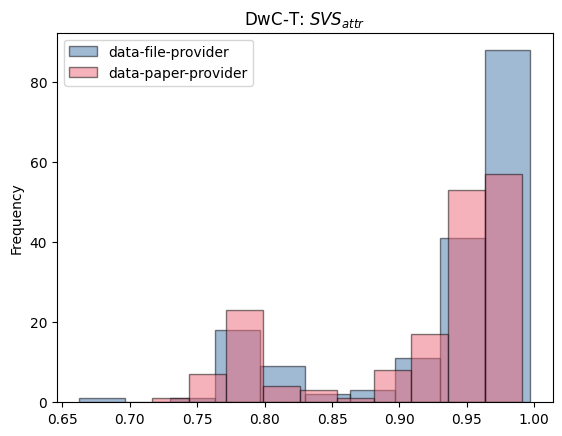

In [537]:
ax = dwc_data_file_svs_attr_metric["svs_attr"].plot.hist(alpha=0.5, edgecolor="k", label="data-file-provider")
ax = dwc_data_paper_svs_attr_metric["svs_attr"].plot.hist(alpha=0.5, edgecolor="k", label="data-paper-provider", ax = ax)
ax.set_title("DwC-T: $SVS_{attr}$")
ax.legend()
plt.show()

##### EML

In [544]:
display(eml_data_file_svs_attr_metric.describe())

,case_id,svs_attr
count,150.000000,150.000000
mean,88.686667,0.346931
std,53.070314,0.337972
min,0.000000,0.000000
25%,42.250000,0.000000
50%,88.500000,0.458999
75%,134.750000,0.682049
max,178.000000,0.835946


In [545]:
display(eml_data_paper_svs_attr_metric.describe())

,case_id,svs_attr
count,148.000000,148.000000
mean,92.864865,0.396438
std,50.983477,0.336044
min,0.000000,0.000000
25%,49.750000,0.000000
50%,96.000000,0.621671
75%,137.250000,0.700281
max,178.000000,0.830288


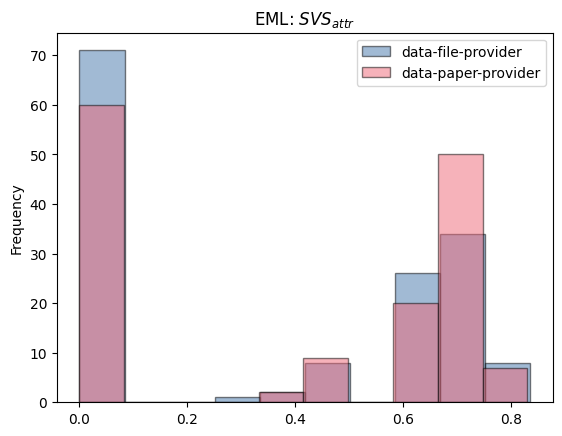

In [539]:
ax = eml_data_file_svs_attr_metric["svs_attr"].plot.hist(alpha=0.5, edgecolor="k", label="data-file-provider")
ax = eml_data_paper_svs_attr_metric["svs_attr"].plot.hist(alpha=0.5, edgecolor="k", label="data-paper-provider", ax = ax)
ax.set_title("EML: $SVS_{attr}$")
ax.legend()
plt.show()

#### Support

##### DwC-T

In DwC-T Attributes are used to describe the contents of the data files in terms of controlled community terms (i.e. Darwin Core vocabulary and ontology, and other relevant standards).

In [571]:
%%sql dwc_data_file_inspect_attrs <<
SELECT node_tag, cos_sim_attributes
FROM dwc_data_file_provider_cons_gt_nodes_with_attributes

Running query in 'duckdb'

In [572]:
dwc_data_file_inspect_attrs.describe()

,cos_sim_attributes
count,7746.000000
mean,0.914263
std,0.237642
min,-1.000000
25%,0.867690
50%,1.000000
75%,1.000000
max,1.000000


(7746, 2)

(5278, 2)

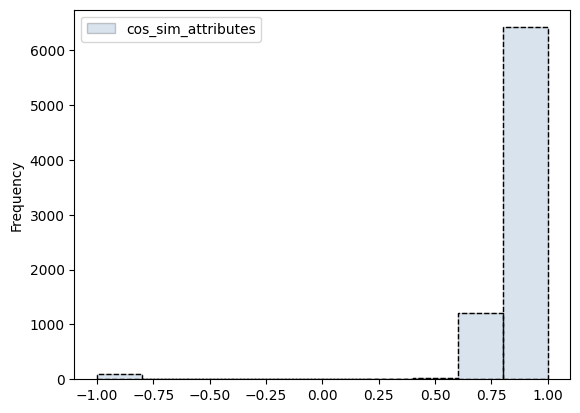

In [573]:
dwc_data_file_inspect_attrs["cos_sim_attributes"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=False)
dwc_data_file_inspect_attrs["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
display(dwc_data_file_inspect_attrs.shape)
display(dwc_data_file_inspect_attrs[dwc_data_file_inspect_attrs["cos_sim_attributes"] == 1.0].shape)

In [574]:
%%sql dwc_data_paper_inspect_attrs <<
SELECT node_tag, cos_sim_attributes
FROM dwc_data_paper_provider_cons_gt_nodes_with_attributes

Running query in 'duckdb'

In [575]:
dwc_data_paper_inspect_attrs.describe()

,cos_sim_attributes
count,7711.000000
mean,0.893094
std,0.291561
min,-1.000000
25%,0.838413
50%,1.000000
75%,1.000000
max,1.000000


(7711, 2)

(4969, 2)

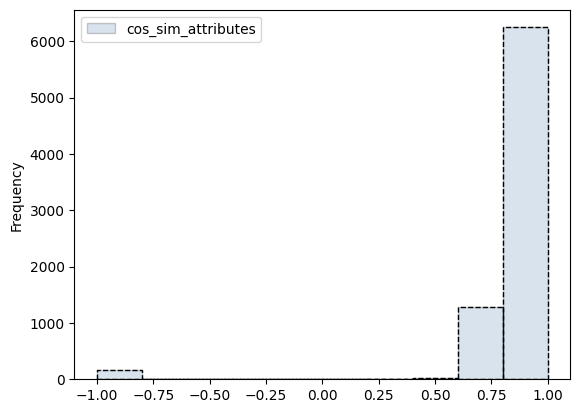

In [576]:
dwc_data_paper_inspect_attrs["cos_sim_attributes"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=False)
dwc_data_paper_inspect_attrs["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
display(dwc_data_paper_inspect_attrs.shape)
display(dwc_data_paper_inspect_attrs[dwc_data_paper_inspect_attrs["cos_sim_attributes"] == 1.0].shape)

> **correlation between providers** 

In [577]:
print("-- Welch's t-test: --")
display(ttest_ind(
    dwc_data_file_inspect_attrs["cos_sim_attributes"],
    dwc_data_paper_inspect_attrs["cos_sim_attributes"],
    equal_var=False
))
print("-- Cohen's d effect size: --")
display(cohen_d(
    dwc_data_file_inspect_attrs["cos_sim_attributes"],
    dwc_data_paper_inspect_attrs["cos_sim_attributes"],
))

-- Welch's t-test: --


TtestResult(statistic=np.float64(4.946665816291981), pvalue=np.float64(7.632265293728595e-07), df=np.float64(14825.179575378957))

-- Cohen's d effect size: --


np.float64(0.07961216212477601)

> **node tag overview**

In [578]:
%%sql
SELECT node_tag, COUNT(1)
FROM dwc_data_file_provider_cons_gt_nodes_with_attributes
GROUP BY 1
ORDER BY 2, 1

Running query in 'duckdb'

,node_tag,count(1)
0,"""{http://rs.tdwg.org/dwc/text/}coreid""",92
1,"""{http://rs.tdwg.org/dwc/text/}extension""",93
2,"""{http://rs.tdwg.org/dwc/text/}archive""",171
3,"""{http://rs.tdwg.org/dwc/text/}core""",174
4,"""{http://rs.tdwg.org/dwc/text/}id""",174
5,"""{http://rs.tdwg.org/dwc/text/}field""",7042


In [579]:
%%sql
SELECT node_tag, COUNT(1)
FROM dwc_data_paper_provider_cons_gt_nodes_with_attributes
GROUP BY 1
ORDER BY 2, 1

Running query in 'duckdb'

,node_tag,count(1)
0,"""{http://rs.tdwg.org/dwc/text/}coreid""",95
1,"""{http://rs.tdwg.org/dwc/text/}extension""",96
2,"""{http://rs.tdwg.org/dwc/text/}archive""",171
3,"""{http://rs.tdwg.org/dwc/text/}core""",174
4,"""{http://rs.tdwg.org/dwc/text/}id""",174
5,"""{http://rs.tdwg.org/dwc/text/}field""",7001


> **correlation per tag**

Pay attention to the results for `{http://rs.tdwg.org/dwc/text/}archive` tag.

In [585]:
shared_unique_tags = list(
    set.intersection(
        set(dwc_data_file_inspect_attrs["node_tag"].unique()),
        set(dwc_data_paper_inspect_attrs["node_tag"].unique()),
    )
)

for tag in shared_unique_tags:
    print(f"\n==== {tag} ====")
    print("-- Welch's t-test: --")
    display(ttest_ind(
        dwc_data_file_inspect_attrs[dwc_data_file_inspect_attrs["node_tag"] == tag]["cos_sim_attributes"],
        dwc_data_paper_inspect_attrs[dwc_data_paper_inspect_attrs["node_tag"] == tag]["cos_sim_attributes"],
        equal_var=False
    ))
    print("-- Cohen's d effect size: --")
    display(cohen_d(
        dwc_data_file_inspect_attrs[dwc_data_file_inspect_attrs["node_tag"] == tag]["cos_sim_attributes"],
        dwc_data_paper_inspect_attrs[dwc_data_paper_inspect_attrs["node_tag"] == tag]["cos_sim_attributes"],
    ))


==== "{http://rs.tdwg.org/dwc/text/}extension" ====
-- Welch's t-test: --


TtestResult(statistic=np.float64(0.2667386652884093), pvalue=np.float64(0.7899744538471482), df=np.float64(180.74671068666316))

-- Cohen's d effect size: --


np.float64(0.03867537486709524)


==== "{http://rs.tdwg.org/dwc/text/}core" ====
-- Welch's t-test: --


...

np.float64(0.006019721530352453)


==== "{http://rs.tdwg.org/dwc/text/}field" ====
-- Welch's t-test: --


TtestResult(statistic=np.float64(1.437929780585659), pvalue=np.float64(0.1504767361591806), df=np.float64(13750.298709311186))

-- Cohen's d effect size: --


np.float64(0.024257602712157697)

In [593]:
%%sql
-- dwc-t X data-file-provider
SELECT node_tag, node_attributes, gt_node_attributes, COUNT(1)
FROM dwc_data_file_provider_cons_gt_nodes_with_attributes
WHERE node_tag = '"{http://rs.tdwg.org/dwc/text/}archive"'::STRING
GROUP BY 1,2,3
ORDER BY 4

Running query in 'duckdb'

,node_tag,node_attributes,gt_node_attributes,count(1)
0,"""{http://rs.tdwg.org/dwc/text/}archive""","{""metadata"":""GAP_001""}","{""metadata"":""eml.xml""}",1
1,"""{http://rs.tdwg.org/dwc/text/}archive""","{""metadata"":""Ascorhynchus hippos Turpaeva, 1994""}","{""metadata"":""eml.xml""}",1
2,"""{http://rs.tdwg.org/dwc/text/}archive""","{""metadata"":""1""}","{""metadata"":""eml.xml""}",1
3,"""{http://rs.tdwg.org/dwc/text/}archive""","{""metadata"":""not-derived-001""}","{""metadata"":""eml.xml""}",59
4,"""{http://rs.tdwg.org/dwc/text/}archive""","{""metadata"":""meta.xml""}","{""metadata"":""eml.xml""}",109


In [594]:
%%sql
-- dwc-t X data-paper-provider
SELECT node_tag, node_attributes, gt_node_attributes, COUNT(1)
FROM dwc_data_paper_provider_cons_gt_nodes_with_attributes
WHERE node_tag = '"{http://rs.tdwg.org/dwc/text/}archive"'::STRING
GROUP BY 1,2,3
ORDER BY 4

Running query in 'duckdb'

,node_tag,node_attributes,gt_node_attributes,count(1)
0,"""{http://rs.tdwg.org/dwc/text/}archive""","{""metadata"":""omit or leave empty""}","{""metadata"":""eml.xml""}",1
1,"""{http://rs.tdwg.org/dwc/text/}archive""","{""metadata"":""omit the `metadata` attribute""}","{""metadata"":""eml.xml""}",1
2,"""{http://rs.tdwg.org/dwc/text/}archive""","{""metadata"":""https://www.gbif.org/dataset/e9ae...","{""metadata"":""eml.xml""}",1
3,"""{http://rs.tdwg.org/dwc/text/}archive""","{""metadata"":""not-derived-001` is unavailable. ...","{""metadata"":""eml.xml""}",1
4,"""{http://rs.tdwg.org/dwc/text/}archive""","{""metadata"":""https://doi.org/10.15468/gwr8mg""}","{""metadata"":""eml.xml""}",1
5,"""{http://rs.tdwg.org/dwc/text/}archive""","{""metadata"":""omit the metadata attribute""}","{""metadata"":""eml.xml""}",2
6,"""{http://rs.tdwg.org/dwc/text/}archive""","{""metadata"":""meta.xml""}","{""metadata"":""eml.xml""}",30
7,"""{http://rs.tdwg.org/dwc/text/}archive""","{""metadata"":""not-derived-001""}","{""metadata"":""eml.xml""}",134


> **per attribute key**

> **per attribute key only for well-inferred hierarchies**

##### EML

In EML, attribute values are instrumental.

> **per case**

In [350]:
%%sql eml_data_file_inspect_attrs <<
SELECT cos_sim_attributes
FROM eml_data_file_provider_cons_gt_nodes_with_attributes

Running query in 'duckdb'

In [351]:
eml_data_file_inspect_attrs.describe()

,cos_sim_attributes
count,180.000000
mean,-0.122967
std,0.827257
min,-1.000000
25%,-1.000000
50%,0.424539
75%,0.571994
max,0.990047


(180, 1)

(0, 1)

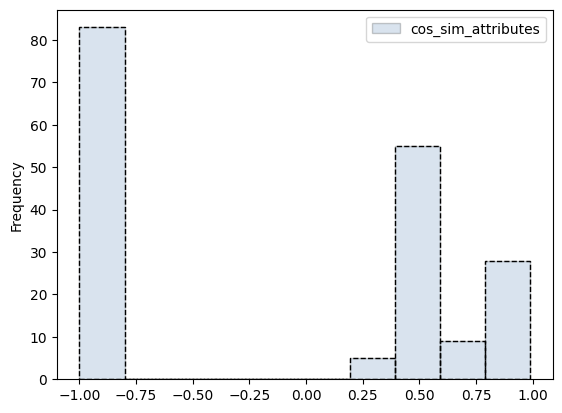

In [352]:
eml_data_file_inspect_attrs["cos_sim_attributes"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=False)
eml_data_file_inspect_attrs["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
display(eml_data_file_inspect_attrs.shape)
display(eml_data_file_inspect_attrs[eml_data_file_inspect_attrs["cos_sim_attributes"] == 1.0].shape)

In [523]:
%%sql eml_data_paper_inspect_attrs <<
SELECT cos_sim_attributes
FROM eml_data_paper_provider_cons_gt_nodes_with_attributes

Running query in 'duckdb'

In [524]:
eml_data_paper_inspect_attrs.describe()

,cos_sim_attributes
count,176.000000
mean,-0.029703
std,0.812901
min,-1.000000
25%,-1.000000
50%,0.477857
75%,0.604676
max,0.990047


(176, 1)

(0, 1)

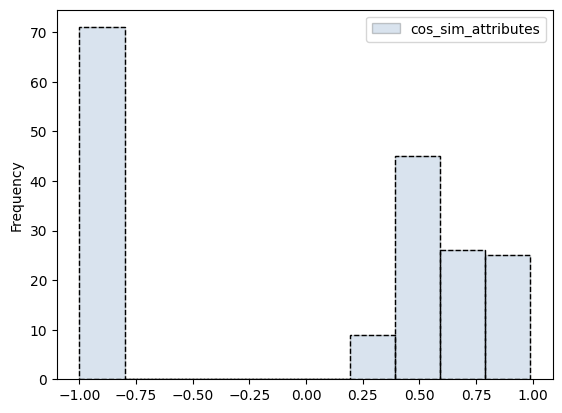

In [356]:
eml_data_paper_inspect_attrs["cos_sim_attributes"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=False)
eml_data_paper_inspect_attrs["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
display(eml_data_paper_inspect_attrs.shape)
display(eml_data_paper_inspect_attrs[eml_data_paper_inspect_attrs["cos_sim_attributes"] == 1.0].shape)

## Step 7: $AIB$ metric

> **Architect involvement balance** in the metadata construction task:

$$
AIB(\hat{m},s,d) = 1 - \frac{|plan(s,d)|}{size_{+a}(\hat{m})}
$$

### Computing

In [ ]:
%%sql architect_involvement_balance <<
CREATE OR REPLACE TABLE architect_involvement_balance AS (
    SELECT 
        case_id, 
        mschema, 
        replace(
            replace(treatment, 'data-focus', 'data-file-provider'),
            'author-focus', 'data-paper-provider'
        ) as treatment_repl,
        concat(mschema, '-x-', treatment_repl) group_tag,
        d.success,
        d.parsed,
        tree_size_with_attrs,
        json_array_length(json_extract(
            d.outcome_json, 
            '$.resolutions[0].verified_gap_derivation_plan.gaps'
        )) AS plan_size,
        (
            1 - (plan_size / tree_size_with_attrs)
        ) AS architect_involvement_balance
    FROM experiment_constructed_tree_info_grand AS d
    WHERE d.parsed::BOOL
);
SELECT * FROM architect_involvement_balance;

### Reporting

In [ ]:
experiment_groups = architect_involvement_balance.groupby(["group_tag"])
experiment_groups["architect_involvement_balance"].describe()

In [ ]:
(
    (
        ("df", 0.993769 - 0.988217),
        ("dp", 0.993856 - 0.988889), 
    ),
    (
        ("df", 0.748941 - 0.631847),
        ("dp", 0.736097 - 0.634146), 
    )
)

In [ ]:
experiment_groups_dir = {name[0]: group for name, group in experiment_groups}

In [ ]:
for name, group in experiment_groups:
    np.log1p(group["architect_involvement_balance"]).plot.hist(alpha=0.7, edgecolor="k")

In [ ]:
# AIB distribution is non-normal
for name, group in experiment_groups:
    display(f"{name[0]=}")
    display(group.describe(include="all").to_latex())
    display(normaltest(group["architect_involvement_balance"]))
    display(normaltest(np.log1p(group["architect_involvement_balance"])))

In [ ]:
display(
    mannwhitneyu(
        experiment_groups_dir["dwc-x-data-file-provider"]["architect_involvement_balance"],
        experiment_groups_dir["dwc-x-data-paper-provider"]["architect_involvement_balance"],
        alternative="greater"
    )
)

In [ ]:
display(
    mannwhitneyu(
        experiment_groups_dir["eml-x-data-file-provider"]["architect_involvement_balance"],
        experiment_groups_dir["eml-x-data-paper-provider"]["architect_involvement_balance"],
        alternative="greater"
    )
)

### Extra Plan Insights

#### Operations

In [ ]:
import re
from lxml import etree

# Define global constant for sanitized namespace replacement
SAMPLE_NS_PREFIX = "http://gap-placeholder.invalid/"

def sanitize_xmlns_gaps(xml_str):
    pattern = r'(xmlns(?::[a-zA-Z0-9_]+)?\s*=\s*["\'])([^"\']*\{gap___[A-Za-z0-9_]+___gap\}[^"\']*)(["\'])'
    
    def replacer(match):
        prefix, gap_val, suffix = match.groups()
        safe_uri = SAMPLE_NS_PREFIX + gap_val
        return f"{prefix}{safe_uri}{suffix}"
        
    return re.sub(pattern, replacer, xml_str)

def find_gap_context_lxml(xml_string, target_gap):
    gap_uri_target = SAMPLE_NS_PREFIX + target_gap
    parser = etree.XMLParser(recover=True)
    
    root = etree.fromstring(xml_string.encode('utf-8'), parser=parser)
    for elem in root.iter():
        tag_name = etree.QName(elem).localname

        # 1. Check Namespace Declarations (xmlns)
        for ns_prefix, ns_url in elem.nsmap.items():
            if ns_url and (target_gap in ns_url or gap_uri_target in ns_url):
                attr_name = f"xmlns:{ns_prefix}" if ns_prefix else "xmlns"
                return {
                    "enclosing_tag": tag_name,
                    "type": "namespace_attribute",
                    "attribute_name": attr_name
                }

        # 2. Check Standard Attributes
        for attr_name, attr_val in elem.attrib.items():
            clean_attr = etree.QName(attr_name).localname
            if target_gap in attr_val or gap_uri_target in attr_val:
                return {
                    "enclosing_tag": tag_name,
                    "type": "attribute",
                    "attribute_name": clean_attr
                }

        # 3. Check Text Nodes
        if elem.text and target_gap in elem.text:
            return {
                "enclosing_tag": tag_name,
                "type": "element_text",
                "attribute_name": 'n/a',
            }

    return {"enclosing_tag": None, "type": None, "attribute_name": None}

In [ ]:
import re
import xml.etree.ElementTree as ET

SAMPLE_NS_PREFIX = "http://gap-placeholder.invalid/"

def remove_gap_braces(xml_str: str) -> str:
    return xml_str.replace("{{", "__").replace("}}", '__')

def sanitize_xmlns_gaps(xml_str: str) -> str:
    pattern = r'(xmlns(?::[a-zA-Z0-9_]+)?\s*=\s*["\'])([^"\']*\{\{GAP_[^\}\}]+\}\}[^"\']*)(["\'])'
    
    def replacer(match):
        prefix, gap_val, suffix = match.groups()
        safe_uri = SAMPLE_NS_PREFIX + gap_val
        return f"{prefix}{safe_uri}{suffix}"
        
    return re.sub(pattern, replacer, xml_str)

def get_element_path(elem: ET.Element, parent_map: dict) -> str:
    """Helper to trace path from root element to the given element."""
    if elem is None:
        return None
    path = []
    curr = elem
    while curr is not None:
        tag_name = curr.tag.split('}')[-1] if '}' in curr.tag else curr.tag
        path.append(tag_name)
        curr = parent_map.get(curr)
    return "/" + "/".join(reversed(path))

def find_gap_context_etree(xml_string: str, target_gap: str) -> dict:
    gap_uri_target = SAMPLE_NS_PREFIX + target_gap
    
    sanitized_xml = sanitize_xmlns_gaps(xml_string)
    root = ET.fromstring(sanitized_xml)
    
    # Map each child element to its immediate parent node
    parent_map = {child: parent for parent in root.iter() for child in parent}

    for elem in root.iter():
        tag_name = elem.tag.split('}')[-1] if '}' in elem.tag else elem.tag
        current_path = get_element_path(elem, parent_map)

        # 1. Check Namespace Declarations / Tag Names
        if target_gap in elem.tag or gap_uri_target in elem.tag:
            return {
                "enclosing_tag": tag_name,
                "type": "namespace_attribute",
                "attribute_name": "xmlns",
                "enclosing_path": current_path
            }

        # 2. Check Standard Attributes
        for attr_name, attr_val in elem.attrib.items():
            clean_attr = attr_name.split('}')[-1] if '}' in attr_name else attr_name
            if target_gap in attr_val or gap_uri_target in attr_val:
                return {
                    "enclosing_tag": tag_name,
                    "type": "attribute",
                    "attribute_name": clean_attr,
                    "enclosing_path": current_path
                }

        # 3. Check Text Content (Inside <elem>...</elem>)
        if elem.text and target_gap in elem.text:
            return {
                "enclosing_tag": tag_name,
                "type": "element_text",
                "attribute_name": 'n/a',
                "enclosing_path": current_path
            }

        # 4. Check Tail Text (Text after </elem> before parent closure or sibling)
        if elem.tail and target_gap in elem.tail:
            parent = parent_map.get(elem)
            parent_tag = (parent.tag.split('}')[-1] if '}' in parent.tag else parent.tag) if parent is not None else root.tag
            parent_path = get_element_path(parent, parent_map) if parent is not None else current_path
            return {
                "enclosing_tag": parent_tag,
                "type": "element_text",
                "attribute_name": 'n/a',
                "enclosing_path": parent_path
            }

    return {"enclosing_tag": None, "type": None, "attribute_name": None, "enclosing_path": None}

In [ ]:
def find_gap_context_json(tree_string: str, target_gap: str) -> str:
    clean_tree_string = sanitize_xmlns_gaps(cleanup_special_characters(remove_gap_braces(tree_string)))
    context = find_gap_context_etree(clean_tree_string, remove_gap_braces(target_gap))
    return json.dumps(context)

In [ ]:
try:
    conn.remove_function("find_gap_context_json")
except Exception as e:
    print(e)
conn.create_function("find_gap_context_json", find_gap_context_json)

#### Computing

In [ ]:
%%sql plan_details <<
CREATE OR REPLACE TABLE plan_details AS (
    SELECT 
        d.case_id,
        d.mschema, 
        d.treatment,
        replace(
            replace(d.treatment, 'data-focus', 'data-file-provider'),
            'author-focus', 'data-paper-provider'
        ) as treatment_repl,
        concat(d.mschema, '-x-', treatment_repl) AS group_tag,
        d.success,
        d.parsed,
        d.outcome_json,
        pgs.*,
        json_extract_string(pgs.value, '$.gap_id') AS gap_id,
        json_extract_string(pgs.value, '$.gap_type') AS gap_type,
        json_extract_string(pgs.value, '$.gap_description') AS gap_description,
        json_extract_string(pgs.value, '$.gap_replacement_pattern') AS gap_replacement_pattern,
        json_extract_string(pgs.value, '$.gap_scope_files') AS gap_scope_files,
        json_extract_string(pgs.value, '$.gap_derivation_request') AS gap_derivation_request,
        split(split(gap_replacement_pattern, ':')[3], '}}')[1] AS gap_replacement_pattern_tag,
        split(trim(gap_replacement_pattern, '"'), ':')[1] AS gap_replacement_pattern_id,
        json_extract_string(
            d.outcome_json, 
            '$.resolutions[0].architect_xml_blueprint.content'
        ) AS architect_xml_blueprint,
        json_extract_string(
            d.outcome_json, 
            '$.resolutions[0].working_copy_xml_blueprint.content'
        ) AS working_copy_xml_blueprint,
        -- find_gap_context_json(architect_xml_blueprint, gap_id) AS gap_context,
        find_gap_context_json(architect_xml_blueprint, gap_replacement_pattern)  AS gap_context,
        json_extract_string(gap_context, '$.enclosing_tag') AS gap_enclosing_tag,
        json_extract_string(gap_context, '$.type') AS gap_context_type,
        json_extract_string(gap_context, '$.attribute_name') AS gap_enclosing_attribute_name,
        json_extract_string(gap_context, '$.enclosing_path') AS gap_enclosing_path,
    
        find_gap_context_json(architect_xml_blueprint, gap_replacement_pattern_id)  AS gap_context_by_id,
        json_extract_string(gap_context_by_id, '$.enclosing_tag') AS gap_enclosing_tag_by_id,
        json_extract_string(gap_context_by_id, '$.type') AS gap_context_type_by_id,
        json_extract_string(gap_context_by_id, '$.attribute_name') AS gap_enclosing_attribute_name_by_id,
    FROM experiment_constructed_tree_info_grand AS d,
        json_each(json_extract(
            d.outcome_json, 
            '$.resolutions[0].verified_gap_derivation_plan.gaps'
        )) AS pgs,
    WHERE d.parsed::BOOL
    ORDER BY d.case_id, group_tag
);
SELECT * FROM plan_details;

#### Reporting

In [ ]:
plan_details.describe(include="all")

In [ ]:
%%sql failed_plan_details <<
SELECT * 
FROM plan_details
WHERE gap_context_type IS NULL AND gap_context_type_by_id IS NULL

In [ ]:
%%sql diverging_plan_details <<
SELECT * 
FROM plan_details
WHERE gap_context <> gap_context_by_id
    AND gap_context_type IS NOT NULL AND gap_context_type_by_id IS NOT NULL

In [ ]:
%%sql aligned_plan_details <<
SELECT * 
FROM plan_details
WHERE gap_context = gap_context_by_id
    AND gap_context_type IS NOT NULL AND gap_context_type_by_id IS NOT NULL

In [ ]:
%%sql correct_plan_details_percentage <<
WITH aligned_count_per_case_per_group AS (
    SELECT case_id, group_tag, count(*) AS count_aligned
    FROM plan_details
    WHERE gap_context = gap_context_by_id
        AND gap_context_type IS NOT NULL AND gap_context_type_by_id IS NOT NULL
    GROUP BY 1,2
), all_plan_details AS (
    SELECT case_id, group_tag, count(*) AS count_total
    FROM plan_details
    GROUP BY 1,2
), joined_plan_details AS (
    SELECT a.case_id, a.group_tag, a.count_aligned, t.count_total
    FROM aligned_count_per_case_per_group AS a
        JOIN all_plan_details AS t
            ON a.case_id = t.case_id AND a.group_tag = t.group_tag
) 
SELECT case_id, group_tag, (count_aligned / count_total * 100) AS aligned_percentage
FROM joined_plan_details 

In [ ]:
%%sql 
WITH aligned_count_per_case_per_group AS (
    SELECT case_id, group_tag, count(*) AS count_aligned
    FROM plan_details
    WHERE gap_context = gap_context_by_id
        AND gap_context_type IS NOT NULL AND gap_context_type_by_id IS NOT NULL
    GROUP BY 1,2
), all_plan_details AS (
    SELECT case_id, group_tag, count(*) AS count_total
    FROM plan_details
    GROUP BY 1,2
), joined_plan_details AS (
    SELECT a.case_id, a.group_tag, a.count_aligned, t.count_total, (a.count_aligned = t.count_total)::INT AS aligned_count
    FROM aligned_count_per_case_per_group AS a
        JOIN all_plan_details AS t
            ON a.case_id = t.case_id AND a.group_tag = t.group_tag
), aligned_percentage AS (
    SELECT 
        group_tag, 
        SUM(aligned_count) AS count_fully_aligned, 
        COUNT(1) as count_total, 
    FROM joined_plan_details 
    GROUP BY 1
    ORDER BY group_tag
)
SELECT group_tag, (count_fully_aligned / count_total) * 100 AS aligned_percentage
FROM aligned_percentage

In [ ]:
correct_plan_details_percentage.groupby(["group_tag"]).describe()

In [ ]:
correct_plan_details_percentage[
    correct_plan_details_percentage["aligned_percentage"] < 100.00
].groupby(["group_tag"])["aligned_percentage"].describe()

In [ ]:
correct_plan_details_percentage[
    correct_plan_details_percentage["aligned_percentage"] < 100.00
].groupby(["group_tag"])["aligned_percentage"].plot.hist(
    alpha=0.5, edgecolor="k", legend=True, 
)

In [ ]:
failed_plan_details.describe()

In [ ]:
diverging_plan_details.describe()

In [ ]:
failed_plan_details

In [ ]:
print(failed_plan_details["case_id"].to_list()[0])
print("---")
print(failed_plan_details["outcome_json"].to_list()[0])
print("---")
print(failed_plan_details["gap_id"].to_list()[0])
print("---")
print(failed_plan_details["gap_replacement_pattern"].to_list()[0])
print("---")
print(failed_plan_details["gap_replacement_pattern_id"].to_list()[0])
print("---")
print(failed_plan_details["architect_xml_blueprint"].to_list()[0])
print("---")
print(failed_plan_details["working_copy_xml_blueprint"].to_list()[0])

In [ ]:
failed_plan_details.fillna(0).groupby(
    [
        "group_tag", 
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count()

In [ ]:
diverging_plan_details

In [ ]:
diverging_plan_details.fillna(0).groupby(
    [
        "group_tag", 
        "gap_replacement_pattern",
        "gap_id",
        "gap_description",
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count()

In [ ]:
diverging_plan_details.groupby(
    [
        "group_tag", 
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count() 

In [ ]:
aligned_plan_details.groupby(
    [
        "group_tag", 
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count() 

In [ ]:
plan_details.groupby(
    [
        "group_tag", 
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count()

In [ ]:
aligned_plan_details.groupby(
    [
        "group_tag", 
        "gap_context_type",
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count()

In [ ]:
aligned_plan_details[
    aligned_plan_details["mschema"] == "dwc"
].groupby(
    [
        "group_tag", 
        "gap_context_type",
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count()

In [ ]:
%%sql
WITH archive_occuring AS (
    SELECT group_tag, case_id, gap_enclosing_tag, COUNT(1) AS count_occurence, (COUNT(1) > 0)::INT AS has_occurrence
    FROM aligned_plan_details
    WHERE gap_enclosing_attribute_name = 'metadata'
    GROUP BY 1,2,3
    ORDER BY has_occurrence DESC
)
SELECT 
    group_tag, 
    SUM(has_occurrence), 
    mean(count_occurence), 
    stddev(count_occurence), 
    MAX(count_occurence), 
    median(count_occurence),
    (SUM(has_occurrence) / 174 * 100) AS occurs_percentage
FROM archive_occuring AS ao
GROUP BY group_tag
ORDER BY group_tag

In [ ]:
%%sql
WITH archive_occuring AS (
    SELECT group_tag, case_id, gap_enclosing_tag, COUNT(1) AS count_occurence, (COUNT(1) > 0)::INT AS has_occurrence
    FROM aligned_plan_details
    WHERE gap_enclosing_attribute_name = 'term'
    GROUP BY 1,2,3
    ORDER BY has_occurrence DESC
)
SELECT 
    group_tag, 
    SUM(has_occurrence), 
    mean(count_occurence), 
    stddev(count_occurence), 
    MAX(count_occurence), 
    median(count_occurence),
    (SUM(has_occurrence) / 174 * 100) AS occurs_percentage
FROM archive_occuring AS ao
GROUP BY group_tag
ORDER BY group_tag

In [ ]:
%%sql
WITH archive_occuring AS (
    SELECT group_tag, case_id, gap_enclosing_tag, COUNT(1) AS count_occurence, (COUNT(1) > 0)::INT AS has_occurrence
    FROM aligned_plan_details
    WHERE gap_enclosing_attribute_name = 'rowType'
    GROUP BY 1,2,3
    ORDER BY has_occurrence DESC
)
SELECT 
    group_tag, 
    SUM(has_occurrence), 
    mean(count_occurence), 
    stddev(count_occurence), 
    MAX(count_occurence), 
    median(count_occurence),
    (SUM(has_occurrence) / 174 * 100) AS occurs_percentage
FROM archive_occuring AS ao
GROUP BY group_tag
ORDER BY group_tag

In [ ]:
%%sql
WITH archive_occuring AS (
    SELECT group_tag, case_id, gap_enclosing_tag, COUNT(1) AS count_occurence, (COUNT(1) > 0)::INT AS has_occurrence
    FROM aligned_plan_details
    WHERE gap_enclosing_attribute_name = 'index'
    GROUP BY 1,2,3
    ORDER BY has_occurrence DESC
)
SELECT 
    group_tag, 
    SUM(has_occurrence), 
    mean(count_occurence), 
    stddev(count_occurence), 
    MAX(count_occurence), 
    median(count_occurence),
    (SUM(has_occurrence) / 174 * 100) AS occurs_percentage
FROM archive_occuring AS ao
GROUP BY group_tag
ORDER BY group_tag

In [ ]:
%%sql
SELECT group_tag, gap_context_type, COUNT(1)
FROM aligned_plan_details
WHERE mschema = 'eml'
GROUP by 1,2

In [ ]:
%%sql
SELECT group_tag, gap_enclosing_tag, COUNT(1) AS count_occurrence
FROM aligned_plan_details
WHERE mschema = 'eml'
    AND treatment_repl = 'data-file-provider'
    AND gap_context_type = 'element_text'
GROUP by 1,2
ORDER BY count_occurrence DESC
LIMIT 15

In [ ]:
%%sql
SELECT group_tag, gap_enclosing_tag, COUNT(1) AS count_occurrence
FROM aligned_plan_details
WHERE mschema = 'eml'
    AND treatment_repl = 'data-paper-provider'
    AND gap_context_type = 'element_text'
GROUP by 1,2
ORDER BY count_occurrence DESC
LIMIT 15

In [ ]:
import re
import pandas as pd


def map_eml_path_to_category(path: str, tag: str = "") -> str:
    """Maps an EML gap_enclosing_path (and optional tag) to one of four EML categories:

    (c1) attribution
    (c2) study description
    (c3) spatio-temporal elements
    (c4) biodiversity classification
    """
    path_lower = str(path).lower()
    tag_lower = str(tag).lower()

    # (c4) Biodiversity classification
    if any(
        term in path_lower
        for term in [
            "taxonomic",
            "taxon",
            "species",
            "triatominae",  # Domain-specific dataset context in your tail
        ]
    ):
        return "c4"

    # (c3) Spatio-temporal elements
    if any(
        term in path_lower
        for term in [
            "studyareadescription",
            "geographiccoverage",
            "temporalcoverage",
            "eventdaterange",
            "enddate",
            "startdate",
            "date",
            "spatial",
            "temporal",
            "observedcontext",
        ]
    ):
        return "c3"

    # (c1) Attribution
    if any(
        term in path_lower
        for term in [
            "creator",
            "personnel",
            "contact",
            "individualname",
            "surname",
            "givenname",
            "userid",
            "funding",
            "organizationname",
            "publisher",
            "associatedparty",
            "role",
            "license",
            "accessrights",
        ]
    ):
        return "c1"

    # (c2) Study description
    if any(
        term in path_lower
        for term in [
            "methodstep",
            "methods",
            "qualitycontrol",
            "instrumentation",
            "sampling",
            "designdescription",
            "maintenance",
            "abstract",
            "title",
            "descriptor",
            "provenance",
            "processing",
            "laboratoryanalysis",
        ]
    ) or tag_lower in ["title", "abstract", "instrumentation"]:
        return "c2"

    
    # (c+) Additional Metadata
    if any(
        term in path_lower
        for term in [
            "additionalmetadata"
        ]
    ):
        return "c+"
    
    # Fallback default for unmatched custom metadata
    return "other / unmapped"


# Example application to a DataFrame:
def categorize_eml_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    """Adds a 'category' column to the dataset based on gap_enclosing_path and

    gap_enclosing_tag.
    """
    df_copy = df.copy()
    df_copy["category"] = df_copy.apply(
        lambda row: map_eml_path_to_category(
            row["gap_enclosing_path"], row.get("gap_enclosing_tag", "")
        ),
        axis=1,
    )
    return df_copy

In [ ]:
%%sql eml_dfp_most_frequent_tags <<
SELECT group_tag, gap_enclosing_tag, gap_enclosing_path, COUNT(1) AS count_occurrence
FROM aligned_plan_details
WHERE mschema = 'eml'
    AND treatment_repl = 'data-file-provider'
    AND gap_context_type = 'element_text'
GROUP by 1,2,3
ORDER BY group_tag, count_occurrence DESC

In [ ]:
display(eml_dfp_most_frequent_tags.head(150))
display(eml_dfp_most_frequent_tags.describe(include="all").to_latex())
display(eml_dfp_most_frequent_tags.head(50).to_latex())

In [ ]:
eml_dfp_most_frequent_tags_cats = categorize_eml_dataframe(eml_dfp_most_frequent_tags)
eml_dfp_most_frequent_tags_cats.groupby("category").count()

In [ ]:
eml_dfp_most_frequent_tags_cats.groupby("category").describe()

In [ ]:
eml_dfp_most_frequent_tags_cats[
    eml_dfp_most_frequent_tags_cats["category"] == "c4"
]

In [ ]:
%%sql eml_dpp_most_frequent_tags <<
SELECT group_tag, gap_enclosing_tag, gap_enclosing_path, COUNT(1) AS count_occurrence
FROM aligned_plan_details
WHERE mschema = 'eml'
    AND treatment_repl = 'data-paper-provider'
    AND gap_context_type = 'element_text'
GROUP by 1,2,3
ORDER BY group_tag, count_occurrence DESC

In [ ]:
display(eml_dpp_most_frequent_tags.head(50))
display(eml_dpp_most_frequent_tags.describe(include="all").to_latex())
display(eml_dpp_most_frequent_tags.head(50).to_latex())

In [ ]:
eml_dpp_most_frequent_tags_cats = categorize_eml_dataframe(eml_dpp_most_frequent_tags)
eml_dpp_most_frequent_tags_cats.groupby("category").count()

In [ ]:
eml_dpp_most_frequent_tags_cats.groupby("category").describe()

In [ ]:
eml_dpp_most_frequent_tags_cats[
    eml_dpp_most_frequent_tags_cats["category"] == "c+"
]

In [ ]:
%%sql
SELECT group_tag, gap_enclosing_attribute_name, COUNT(1) AS count_occurrence
FROM aligned_plan_details
WHERE mschema = 'eml'
    -- AND treatment_repl = 'data-paper-provider'
    AND contains(gap_context_type, 'attribute')
GROUP by 1,2
ORDER BY count_occurrence DESC

In [ ]:
for name, group in aligned_plan_details.groupby(
    [
        "group_tag", 
    ]
):
    print("---")
    print(f"{name=}")
    display(group.groupby(["gap_context_type"]).count())
    display(group.groupby(["gap_context_type", "gap_enclosing_tag"]).count())
    
    display(group[
            group["gap_context_type"] == "attribute"
    ].groupby(
        ["gap_context_type", "gap_enclosing_tag", "gap_enclosing_attribute_name"]
    ).count())

    display(group[
            group["gap_context_type"] == "element_text"
    ].groupby(
        ["gap_context_type", "gap_enclosing_tag", "gap_enclosing_attribute_name"]
    ).count())

    